# GitHub User Activity Prediction — RDL (Assignment 2)

**Run order:** Steps 1–10 once → Steps 11–12 for each E3+ variant → Step 13 after reviewing benchmark results → Step 14 for report figures. **Do not switch `RUN_MODE` midway.** Benchmark and final workflows deliberately have separate model objects, scalers, thresholds, and saved files.

**Benchmark:** train cutoffs Aug 16–Sep 13 (Taiwan), calibrate Sep 20, evaluate Sep 27/Oct 4/Oct 11/Oct 18.

**Final retraining:** fit on Aug 16–Oct 11, calibrate Oct 18, and predict the official Nov 22 test cutoff. Model selection uses benchmark weeks; consequently those weeks become *development/selection data*, not an untouched final test estimate.

> **Note:** All dates are Taiwan-local unless explicitly marked UTC-naive.

# Step 1 — Install dependencies and prepare GH Archive data

Install packages / preprocess the data if they are not already available. Large download and preprocessing commands may be skipped when their outputs exist.

In [ ]:
!pip install torch-geometric

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.3/1.3 MB 42.8 MB/s  0:00:00


In [ ]:
!pip install -q graphviz

# Install Graphviz renderer if not already installed
!apt-get install -y -qq graphviz

In [ ]:
!pip install --no-deps --no-index pyg_lib -f "https://data.pyg.org/whl/torch-2.14.0+cu130.html"

# After that, restart kernel, then run the subsequent code to check the dependencies

Looking in links: https://data.pyg.org/whl/torch-2.14.0+cu130.html
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.0/5.0 MB 74.5 MB/s  0:00:00


In [ ]:
import torch
import torch_geometric
import pyg_lib
import numpy as np
import pandas as pd
import math
import subprocess
import joblib
import copy
import lightgbm as lgb
import sys
import platform

from torch_geometric.typing import WITH_PYG_LIB
from torch_geometric.nn import HeteroConv, SAGEConv
from torch_geometric.loader import NeighborLoader
from torch_geometric.data import HeteroData
from collections import OrderedDict
from torch import nn
from torch.nn import functional as F
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score
)
from graphviz import Digraph
from IPython.display import display, SVG
from pathlib import Path
from datetime import datetime
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import f1_score, classification_report

/usr/local/lib/python3.13/dist-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


In [ ]:
print("Python:", sys.version)
print("OS:", platform.system())
print("Architecture:", platform.machine())
print("PyTorch:", torch.__version__)
print("CUDA version:", torch.version.cuda)
print("CUDA available:", torch.cuda.is_available())
print("PyG:", torch_geometric.__version__)
print("pyg-lib:", pyg_lib.__version__)
print("PyG backend available:", WITH_PYG_LIB)

Python: 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]
OS: Linux
Architecture: x86_64
PyTorch: 2.14.1+cu130
CUDA version: 13.0
CUDA available: True
PyG: 2.8.1
pyg-lib: 0.9.0+pt214cu130
PyG backend available: True


In [ ]:
!git clone --depth 1 https://github.com/nycubigdata-2026fall/BigData2026-Assignment2.git assignment2

Cloning into 'assignment2'...
remote: Enumerating objects: 11, done.
remote: Counting objects: 100% (11/11), done.
remote: Compressing objects: 100% (10/10), done.
remote: Total 11 (delta 1), reused 11 (delta 1), pack-reused 0 (from 0)
Receiving objects: 100% (11/11), 135.25 KiB | 1.17 MiB/s, done.
Resolving deltas: 100% (1/1), done.


In [ ]:
!wget -P RAW_DATA_FOLDER https://data.gharchive.org/2026-11-{01..11}-{0..23}.json.gz

--2026-11-13 11:56:37--  https://data.gharchive.org/2026-11-01-0.json.gz
Resolving data.gharchive.org (data.gharchive.org)... 188.114.97.0, 188.114.96.0, 2a06:98c1:3120::, ...
Connecting to data.gharchive.org (data.gharchive.org)|188.114.97.0|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 6240448 (6.0M) [application/gzip]
Saving to: ‘RAW_DATA_FOLDER/2026-11-01-0.json.gz’

2026-11-01-0.json.g 100%[===================>]   5.95M  --.-KB/s    in 0.05s   

2026-11-13 11:56:37 (121 MB/s) - ‘RAW_DATA_FOLDER/2026-11-01-0.json.gz’ saved [6240448/6240448]

--2026-11-13 11:56:37--  https://data.gharchive.org/2026-11-01-1.json.gz
Reusing existing connection to data.gharchive.org:443.
HTTP request sent, awaiting response... 200 OK
Length: 6320143 (6.0M) [application/gzip]
Saving to: ‘RAW_DATA_FOLDER/2026-11-01-1.json.gz’

2026-11-01-1.json.g 100%[===================>]   6.03M  --.-KB/s    in 0.04s   

2026-11-13 11:56:37 (168 MB/s) - ‘RAW_DATA_FOLDER/2026-11-01-1.json.gz’

In [ ]:
!wget -P RAW_DATA_FOLDER https://data.gharchive.org/2026-10-{01..31}-{0..23}.json.gz

In [ ]:
!wget -P RAW_DATA_FOLDER https://data.gharchive.org/2026-09-{01..30}-{0..23}.json.gz

Streaming output truncated to the last 5000 lines.
Length: 16579167 (16M) [application/gzip]
Saving to: ‘RAW_DATA_FOLDER/2026-09-10-4.json.gz’

2026-09-10-4.json.g 100%[===================>]  15.81M  --.-KB/s    in 0.09s   

2026-11-13 12:03:04 (170 MB/s) - ‘RAW_DATA_FOLDER/2026-09-10-4.json.gz’ saved [16579167/16579167]

--2026-11-13 12:03:04--  https://data.gharchive.org/2026-09-10-5.json.gz
Reusing existing connection to data.gharchive.org:443.
HTTP request sent, awaiting response... 200 OK
Length: 15661212 (15M) [application/gzip]
Saving to: ‘RAW_DATA_FOLDER/2026-09-10-5.json.gz’

2026-09-10-5.json.g 100%[===================>]  14.94M  --.-KB/s    in 0.07s   

2026-11-13 12:03:04 (200 MB/s) - ‘RAW_DATA_FOLDER/2026-09-10-5.json.gz’ saved [15661212/15661212]

--2026-11-13 12:03:04--  https://data.gharchive.org/2026-09-10-6.json.gz
Reusing existing connection to data.gharchive.org:443.
HTTP request sent, awaiting response... 200 OK
Length: 15480731 (15M) [application/gzip]
Saving to: 

In [ ]:
!wget -P RAW_DATA_FOLDER https://data.gharchive.org/2026-08-{01..31}-{0..23}.json.gz

Streaming output truncated to the last 5000 lines.
Length: 21278231 (20M) [application/gzip]
Saving to: ‘RAW_DATA_FOLDER/2026-08-11-4.json.gz’

2026-08-11-4.json.g 100%[===================>]  20.29M  --.-KB/s    in 0.1s    

2026-11-13 12:07:25 (140 MB/s) - ‘RAW_DATA_FOLDER/2026-08-11-4.json.gz’ saved [21278231/21278231]

--2026-11-13 12:07:25--  https://data.gharchive.org/2026-08-11-5.json.gz
Reusing existing connection to data.gharchive.org:443.
HTTP request sent, awaiting response... 200 OK
Length: 21181147 (20M) [application/gzip]
Saving to: ‘RAW_DATA_FOLDER/2026-08-11-5.json.gz’

2026-08-11-5.json.g 100%[===================>]  20.20M  --.-KB/s    in 0.09s   

2026-11-13 12:07:25 (214 MB/s) - ‘RAW_DATA_FOLDER/2026-08-11-5.json.gz’ saved [21181147/21181147]

--2026-11-13 12:07:25--  https://data.gharchive.org/2026-08-11-6.json.gz
Reusing existing connection to data.gharchive.org:443.
HTTP request sent, awaiting response... 200 OK
Length: 21317291 (20M) [application/gzip]
Saving to: 

In [ ]:
!wget -P RAW_DATA_FOLDER https://data.gharchive.org/2026-07-{01..31}-{0..23}.json.gz

Streaming output truncated to the last 5000 lines.
Length: 21232946 (20M) [application/gzip]
Saving to: ‘RAW_DATA_FOLDER/2026-07-11-4.json.gz’

2026-07-11-4.json.g 100%[===================>]  20.25M  --.-KB/s    in 0.1s    

2026-11-13 12:10:40 (183 MB/s) - ‘RAW_DATA_FOLDER/2026-07-11-4.json.gz’ saved [21232946/21232946]

--2026-11-13 12:10:40--  https://data.gharchive.org/2026-07-11-5.json.gz
Reusing existing connection to data.gharchive.org:443.
HTTP request sent, awaiting response... 200 OK
Length: 21075078 (20M) [application/gzip]
Saving to: ‘RAW_DATA_FOLDER/2026-07-11-5.json.gz’

2026-07-11-5.json.g 100%[===================>]  20.10M   118MB/s    in 0.2s    

2026-11-13 12:10:41 (118 MB/s) - ‘RAW_DATA_FOLDER/2026-07-11-5.json.gz’ saved [21075078/21075078]

--2026-11-13 12:10:41--  https://data.gharchive.org/2026-07-11-6.json.gz
Reusing existing connection to data.gharchive.org:443.
HTTP request sent, awaiting response... 200 OK
Length: 20991408 (20M) [application/gzip]
Saving to: 

In [ ]:
!wget -P RAW_DATA_FOLDER https://data.gharchive.org/2026-06-{01..30}-{0..23}.json.gz

Streaming output truncated to the last 5000 lines.
Length: 23390055 (22M) [application/gzip]
Saving to: ‘RAW_DATA_FOLDER/2026-06-10-4.json.gz’

2026-06-10-4.json.g 100%[===================>]  22.31M  7.69MB/s    in 2.9s    

2026-11-13 12:14:33 (7.69 MB/s) - ‘RAW_DATA_FOLDER/2026-06-10-4.json.gz’ saved [23390055/23390055]

--2026-11-13 12:14:33--  https://data.gharchive.org/2026-06-10-5.json.gz
Reusing existing connection to data.gharchive.org:443.
HTTP request sent, awaiting response... 200 OK
Length: 24762880 (24M) [application/gzip]
Saving to: ‘RAW_DATA_FOLDER/2026-06-10-5.json.gz’

2026-06-10-5.json.g 100%[===================>]  23.62M   118MB/s    in 0.2s    

2026-11-13 12:14:33 (118 MB/s) - ‘RAW_DATA_FOLDER/2026-06-10-5.json.gz’ saved [24762880/24762880]

--2026-11-13 12:14:33--  https://data.gharchive.org/2026-06-10-6.json.gz
Reusing existing connection to data.gharchive.org:443.
HTTP request sent, awaiting response... 200 OK
Length: 22555504 (22M) [application/gzip]
Saving to:

In [ ]:
!python /content/assignment2/scripts/preprocess.py --raw /content/RAW_DATA_FOLDER --out /content/assignment2/data/

Step 1: 3936 GH Archive hour files, 2026-06-01-0 to 2026-11-11-23 (UTC).
Step 2: keeping the cohort users' events.
  24/3936 hours read
  48/3936 hours read
  72/3936 hours read
  96/3936 hours read
  120/3936 hours read
  144/3936 hours read
  168/3936 hours read
  192/3936 hours read
  216/3936 hours read
  240/3936 hours read
  264/3936 hours read
  288/3936 hours read
  312/3936 hours read
  336/3936 hours read
  360/3936 hours read
  384/3936 hours read
  408/3936 hours read
  432/3936 hours read
  456/3936 hours read
  480/3936 hours read
  504/3936 hours read
  528/3936 hours read
  552/3936 hours read
  576/3936 hours read
  600/3936 hours read
  624/3936 hours read
  648/3936 hours read
  672/3936 hours read
  696/3936 hours read
  720/3936 hours read
  744/3936 hours read
  768/3936 hours read
  792/3936 hours read
  816/3936 hours read
  840/3936 hours read
  864/3936 hours read
  888/3936 hours read
  912/3936 hours read
  936/3936 hours read
  960/3936 hours read
  984/393

In [ ]:
# !unzip /content/data_jun_nov.zip -d /content/assignment2


Archive:  /content/data_jun_nov.zip
   creating: /content/assignment2/data/
   creating: /content/assignment2/data/db/
  inflating: /content/assignment2/data/db/IssueComments.parquet  
  inflating: /content/assignment2/data/db/Issues.parquet  
  inflating: /content/assignment2/data/db/PRReviewComments.parquet  
  inflating: /content/assignment2/data/db/PRReviews.parquet  
  inflating: /content/assignment2/data/db/PullRequests.parquet  
  inflating: /content/assignment2/data/db/Pushes.parquet  
  inflating: /content/assignment2/data/db/Repositories.parquet  
  inflating: /content/assignment2/data/db/Users.parquet  


# Step 2 — Load the eight relational tables and inspect data quality

In [ ]:
# Load dataset

DATA = "assignment2/data/db"

users = pd.read_parquet(f"{DATA}/Users.parquet")
repos = pd.read_parquet(f"{DATA}/Repositories.parquet")
prs = pd.read_parquet(f"{DATA}/PullRequests.parquet")
issues = pd.read_parquet(f"{DATA}/Issues.parquet")
issue_comments = pd.read_parquet(f"{DATA}/IssueComments.parquet")
reviews = pd.read_parquet(f"{DATA}/PRReviews.parquet")
review_comments = pd.read_parquet(f"{DATA}/PRReviewComments.parquet")
pushes = pd.read_parquet(f"{DATA}/Pushes.parquet")

In [ ]:
# Build tabels registry
tables = {
    "users": users,
    "repos": repos,
    "prs": prs,
    "issues": issues,
    "issue_comments": issue_comments,
    "reviews": reviews,
    "review_comments": review_comments,
    "pushes": pushes
}

for name, df in tables.items():
    print(f"\n{'='*60}")
    print(name.upper())
    print(f"shape: {df.shape}")
    print(df.dtypes)


USERS
shape: (14834, 6)
user_id                    int64
github_user_id             Int64
login                     object
is_bot                   boolean
is_cohort                boolean
first_seen_at     datetime64[ns]
dtype: object

REPOS
shape: (48563, 7)
repo_id                    int64
github_repo_id             Int64
name                      object
owner_login               object
org_id                     Int64
org_login                 object
first_seen_at     datetime64[ns]
dtype: object

PRS
shape: (60262, 18)
pr_id                     int64
github_pr_id              Int64
repo_id                   Int64
number                    Int64
author_id                 Int64
title                    object
draft                   boolean
head_ref                 object
base_ref                 object
head_sha                 object
base_sha                 object
head_repo_id              Int64
is_cross_repo           boolean
created_at       datetime64[ns]
merged_at        date

In [ ]:
# Isolate the cohort users

# Only cohort users receive target labels.
# Non-cohort users can still appear as graph context.
cohort_users = users[users["is_cohort"]==True].copy()


print("All users:", len(users))
print("Cohort users:", len(cohort_users))

All users: 14834
Cohort users: 7745


In [ ]:
# Convert date columns to datetime.dtype
time_columns = {
    "users": ["first_seen_at"],
    "repos": ["first_seen_at"],
    "prs": [
        "created_at",
        "merged_at",
        "closed_at",
        "first_seen_at",
    ],
    "issues": [
        "created_at",
        "closed_at",
        "first_seen_at",
    ],
    "issue_comments": ["created_at"],
    "reviews": [
        "submitted_at",
        "dismissed_at",
        "first_seen_at",
    ],
    "review_comments": ["created_at"],
    "pushes": ["created_at"],
}

for table_name, cols in time_columns.items():
    df = tables[table_name]

    for col in cols:
        if col in df.columns:
            df[col] = pd.to_datetime(df[col])

In [ ]:
print(cohort_users.head())

print("\nPull Requests:")
print(prs.head())

print("\nIssues:")
print(issues.head())

print("\nPushes:")
print(pushes.head())

   user_id   github_user_id             login  is_bot  is_cohort  \
0        0  773153677503676  39c6daa6dd957bd8   False       True   
1        1  191680090512864  036853e375d0da2b   False       True   
2        2  434124789218581  9b3c7fbab4361ade   False       True   
3        3  877784714956504  786636440110cad3   False       True   
4        4  726067014227275  c37f70789bb85453   False       True   

        first_seen_at  
0 2026-06-01 00:00:03  
1 2026-06-01 00:00:04  
2 2026-06-01 00:00:11  
3 2026-06-01 00:00:24  
4 2026-06-01 00:00:24  

Pull Requests:
   pr_id     github_pr_id  repo_id  number  author_id title  draft  \
0      0  815482431038859        6      16       <NA>  None   <NA>   
1      1  222980994825546       15      32       <NA>  None   <NA>   
2      2  564329603090639       22       7         22  None   <NA>   
3      3  808072935366568       35     180       <NA>  None   <NA>   
4      4  724763039218346       41      35       <NA>  None   <NA>   

          

In [ ]:
# Check for missing user IDs
check_cols = {
    "prs.author_id": prs["author_id"],
    "issues.author_id": issues["author_id"],
    "issue_comments.author_id": issue_comments["author_id"],
    "reviews.reviewer_id": reviews["reviewer_id"],
    "review_comments.author_id": review_comments["author_id"],
    "pushes.user_id": pushes["user_id"],
}

for name, s in check_cols.items():
    print(
        name,
        "missing:",
        s.isna().sum(),
        "/",
        len(s)
    )

prs.author_id missing: 36380 / 60262
issues.author_id missing: 0 / 38320
issue_comments.author_id missing: 0 / 20329
reviews.reviewer_id missing: 0 / 16387
review_comments.author_id missing: 0 / 12061
pushes.user_id missing: 0 / 478598


,PushEvent count
2026-10-15,0
2026-10-16,0
2026-10-17,0
2026-10-18,347
2026-10-19,1676
2026-10-20,2005
2026-10-21,2054
2026-10-22,1079
2026-10-23,35
2026-10-24,746


Text(0, 0.5, 'Number of PushEvents')

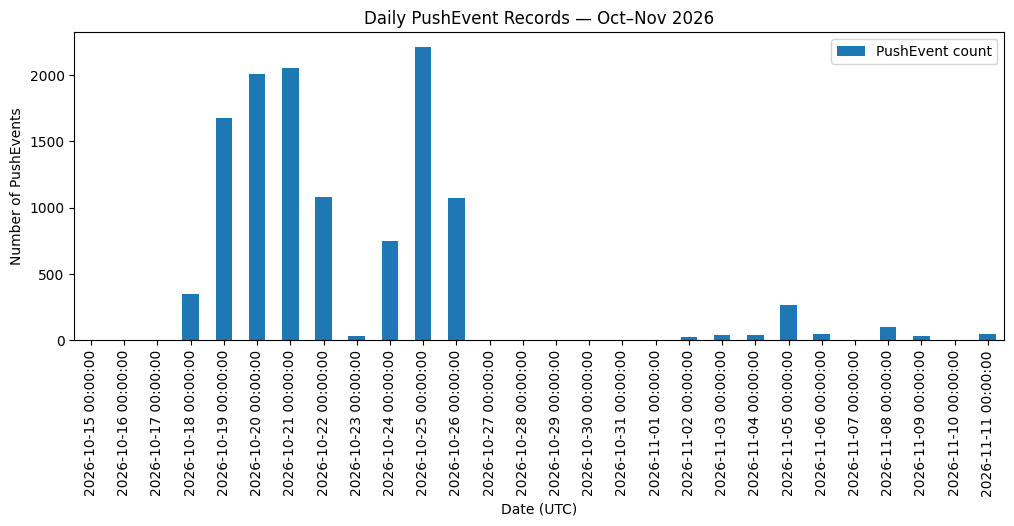

In [ ]:
# Late-October PushEvent coverage diagnostic

push_daily = (
    pd.to_datetime(pushes["created_at"], errors="coerce")
    .dropna()
    .dt.floor("D")
    .value_counts()
    .sort_index()
)

dates = pd.date_range("2026-10-15", "2026-11-11", freq="D")

push_coverage = (
    push_daily.reindex(dates, fill_value=0)
    .rename("PushEvent count")
    .to_frame()
)

display(push_coverage)

ax = push_coverage.plot(
    kind="bar",
    figsize=(12, 4),
    title="Daily PushEvent Records — Oct–Nov 2026"
)

ax.set_xlabel("Date (UTC)")
ax.set_ylabel("Number of PushEvents")

# Step 3 — Define prediction cutoffs and create seven-day labels

In [ ]:
# Fixed development benchmark split. Final retraining is a separate step (Step 13).
RUN_MODE = "benchmark"  # kept for compatibility; do not change to "final" in this notebook

def taiwan_midnight_to_utc_naive(date_string):
    return (pd.Timestamp(date_string, tz="Asia/Taipei")
            .tz_convert("UTC").tz_localize(None))

prediction_times_tw = pd.date_range(
    "2026-08-16", "2026-10-18", freq="7D", tz="Asia/Taipei"
)
prediction_times = prediction_times_tw.tz_convert("UTC").tz_localize(None)
tuning_t = taiwan_midnight_to_utc_naive("2026-09-20")
benchmark_t = taiwan_midnight_to_utc_naive("2026-09-27")
benchmark_end_t = taiwan_midnight_to_utc_naive("2026-10-18")
split_time = tuning_t
assert prediction_times.is_unique and prediction_times.is_monotonic_increasing
assert len(prediction_times) == 10
print("Train: Aug 16–Sep 13 | Tune: Sep 20 | Benchmarks: Sep 27–Oct 18")
print("UTC-naive cutoffs:", list(prediction_times))

Train: Aug 16–Sep 13 | Tune: Sep 20 | Benchmarks: Sep 27–Oct 18
UTC-naive cutoffs: [Timestamp('2026-08-15 16:00:00'), Timestamp('2026-08-22 16:00:00'), Timestamp('2026-08-29 16:00:00'), Timestamp('2026-09-05 16:00:00'), Timestamp('2026-09-12 16:00:00'), Timestamp('2026-09-19 16:00:00'), Timestamp('2026-09-26 16:00:00'), Timestamp('2026-10-03 16:00:00'), Timestamp('2026-10-10 16:00:00'), Timestamp('2026-10-17 16:00:00')]


In [ ]:
# Sanity check: each weekly prediction horizon covers [t, t + 7 days).
# `prediction_times` is already UTC-naive; it is intended for direct comparison
# with the official Parquet timestamp columns (also UTC-naive).
assert prediction_times.is_monotonic_increasing
assert prediction_times.is_unique
print("Weekly prediction cutoffs (UTC-naive):", prediction_times)

Weekly prediction cutoffs (UTC-naive): DatetimeIndex(['2026-08-15 16:00:00', '2026-08-22 16:00:00',
               '2026-08-29 16:00:00', '2026-09-05 16:00:00',
               '2026-09-12 16:00:00', '2026-09-19 16:00:00',
               '2026-09-26 16:00:00', '2026-10-03 16:00:00',
               '2026-10-10 16:00:00', '2026-10-17 16:00:00'],
              dtype='datetime64[ns]', freq=None)


In [ ]:
# Each target is binary: 1 if the user performs the named activity at least once
# during [t, t+7 days), 0 otherwise. PR and issue opening use `created_at`;
# review submission uses `submitted_at`; this is NOT a seven-step daily forecast.
# Labels for training/tuning must come from weeks whose complete interval is present.

# Generate the labels for the specified prediction time range

def create_labels_for_time(t, cohort_users):
    t = pd.Timestamp(t)
    end_t = t + pd.Timedelta(days=7)

    # users who opened PR
    pr_users = set(
        prs.loc[
            (prs["created_at"] >= t) &
            (prs["created_at"] < end_t),
            "author_id"
        ].dropna()
    )

    # users who opened non-PR issues
    issue_users = set(
        issues.loc[
            (issues["is_pull_request"] == False) &
            (issues["created_at"] >= t) &
            (issues["created_at"] < end_t),
            "author_id"
        ].dropna()
    )

    # users who made issue comments
    issue_comment_users = set(
        issue_comments.loc[
            (issue_comments["created_at"] >= t) &
            (issue_comments["created_at"] < end_t),
            "author_id"
        ].dropna()
    )

    # users who submitted PR reviews
    review_users = set(
        reviews.loc[
            (reviews["submitted_at"] >= t) &
            (reviews["submitted_at"] < end_t),
            "reviewer_id"
        ].dropna()
    )

    # users who made PR review comments
    review_comment_users = set(
        review_comments.loc[
            (review_comments["created_at"] >= t) &
            (review_comments["created_at"] < end_t),
            "author_id"
        ].dropna()
    )

    # users who pushed
    push_users = set(
        pushes.loc[
            (pushes["created_at"] >= t) &
            (pushes["created_at"] < end_t),
            "user_id"
        ].dropna()
    )

    samples = cohort_users[["user_id", "github_user_id"]].copy()

    samples["prediction_time"] = t

    samples["open_pr"] = (
        samples["user_id"].isin(pr_users).astype(int)
    )

    samples["open_issue"] = (
        samples["user_id"].isin(issue_users).astype(int)
    )

    samples["issue_comment"] = (
        samples["user_id"].isin(issue_comment_users).astype(int)
    )

    samples["pr_review"] = (
        samples["user_id"].isin(review_users).astype(int)
    )

    samples["pr_review_comment"] = (
        samples["user_id"].isin(review_comment_users).astype(int)
    )

    samples["push"] = (
        samples["user_id"].isin(push_users).astype(int)
    )

    return samples

In [ ]:
# Generate labels for all weekly prediction range

all_samples = []

for t in prediction_times:
    week_samples = create_labels_for_time(
        t,
        cohort_users
    )

    all_samples.append(week_samples)

samples = pd.concat(
    all_samples,
    ignore_index=True
)

samples.shape

(77450, 9)

In [ ]:
samples.head()

,user_id,github_user_id,prediction_time,open_pr,open_issue,issue_comment,pr_review,pr_review_comment,push
0,0,773153677503676,2026-08-15 16:00:00,0,0,0,0,0,0
1,1,191680090512864,2026-08-15 16:00:00,0,0,0,1,0,1
2,2,434124789218581,2026-08-15 16:00:00,0,0,0,0,0,0
3,3,877784714956504,2026-08-15 16:00:00,0,1,0,0,0,1
4,4,726067014227275,2026-08-15 16:00:00,0,0,0,0,0,1


In [ ]:
samples.tail()

,user_id,github_user_id,prediction_time,open_pr,open_issue,issue_comment,pr_review,pr_review_comment,push
77445,14733,824061520867800,2026-10-17 16:00:00,0,0,0,0,0,0
77446,14734,842913579552578,2026-10-17 16:00:00,0,0,0,0,0,0
77447,14770,246137338244841,2026-10-17 16:00:00,0,0,0,0,0,0
77448,14799,507653771228522,2026-10-17 16:00:00,0,0,0,0,0,0
77449,14832,454619326660000,2026-10-17 16:00:00,0,0,0,0,0,0


# Step 4 — Build leakage-aware user history features and temporal splits

## Generate event count e.g. push activity in the last 7/30/90 days & count of unique repos

`row_time_col` controls when a row becomes observable; `activity_time_col` controls when the underlying activity happened. We require both timestamps to be before cutoff `t` to prevent future information from entering historical features.

In [ ]:
def get_activity_window(config, t, days=None):

    df = config["df"]

    row_time = pd.to_datetime(
        df[config["row_time_col"]]
    )

    activity_time = pd.to_datetime(
        df[config["activity_time_col"]]
    )

    # Rows must already be observable at t
    mask = (
        (row_time < t) &
        (activity_time < t)
    )

    # Optional historical activity window
    if days is not None:
        start = t - pd.Timedelta(days=days)
        mask &= activity_time >= start

    return df.loc[mask]

In [ ]:
# Aggregates assume their input rows are already availability-filtered by
# get_activity_window(). The time filter below enforces the requested window again;
# it is intentionally redundant and does not replace the availability guard.

def aggregate_activity(
    df,
    user_col,
    time_col,
    t,
    window_days,
    repo_col="repo_id"
):
    start_t = t - pd.Timedelta(days=window_days)

    mask = (
        (df[time_col] >= start_t) &
        (df[time_col] < t)
    )

    filtered = df.loc[mask]

    # Number of activities
    counts = (
        filtered
        .groupby(user_col)
        .size()
    )

    # Number of distinct repositories
    unique_repos = (
        filtered
        .groupby(user_col)[repo_col]
        .nunique()
    )

    return counts, unique_repos

In [ ]:
# For PRs/issues/reviews, first_seen_at determines availability, NOT the
# activity's occurrence time. Use created_at/submitted_at for the 7/30/90-day
# historical counts and recency; the two timestamps may differ substantially.

activity_configs = {
    "pr": {
        "df": prs,
        "user_col": "author_id",
        "row_time_col": "first_seen_at",
        "activity_time_col": "created_at",
    },
    "issue": {
        "df": issues[issues["is_pull_request"] == False],
        "user_col": "author_id",
        "row_time_col": "first_seen_at",
        "activity_time_col": "created_at",
    },
    "issue_comment": {
        "df": issue_comments,
        "user_col": "author_id",
        "row_time_col": "created_at",
        "activity_time_col": "created_at",
    },
    "review": {
        "df": reviews,
        "user_col": "reviewer_id",
        "row_time_col": "first_seen_at",
        "activity_time_col": "submitted_at",
    },
    "review_comment": {
        "df": review_comments,
        "user_col": "author_id",
        "row_time_col": "created_at",
        "activity_time_col": "created_at",
    },
    "push": {
        "df": pushes,
        "user_col": "user_id",
        "row_time_col": "created_at",
        "activity_time_col": "created_at",
    },
}

## Generate recency features e.g. days_since_last_push

In [ ]:
# Returns one Series indexed by internal user_id; users without a historical
# observation are filled with 999 by the calling feature builder.

def get_days_since_last_activity(config, t):

    historical_df = get_activity_window(
        config,
        t
    )

    last_activity = (
        historical_df
        .groupby(config["user_col"])[
            config["activity_time_col"]
        ]
        .max()
    )

    days_since_last = (
        (t - last_activity)
        .dt.total_seconds()
        / 86400
    )

    return days_since_last

In [ ]:
def create_features_for_time(t, cohort_users):
    """Make historical features at cutoff t without looking into future rows.

    Returns 42 columns excluding IDs/time: 6 activities * 3 windows *
    (count + unique repos) = 36, plus 6 recency columns.
    The temporal MLP adds 6 missing-recency indicators separately.
    """
    features = cohort_users[["user_id", "github_user_id"]].copy()
    features["prediction_time"] = t
    windows = [7, 30, 90]

    for activity, config in activity_configs.items():
        for window in windows:
            # Must pass BOTH: row visible at t, and actual activity in window.
            window_df = get_activity_window(config, t, days=window)
            counts, unique_repos = aggregate_activity(
                df=window_df,
                user_col=config["user_col"],
                time_col=config["activity_time_col"],
                t=t,
                window_days=window,
            )
            features[f"{activity}_count_{window}d"] = (
                features["user_id"].map(counts).fillna(0).astype(int)
            )
            features[f"{activity}_unique_repos_{window}d"] = (
                features["user_id"].map(unique_repos).fillna(0).astype(int)
            )

        # Recency: actual event date, not first_seen_at. A missing history is
        # represented as 999; the neural branch turns this into a missing flag.
        days_since = get_days_since_last_activity(config, t)
        features[f"days_since_last_{activity}"] = (
            features["user_id"].map(days_since).fillna(999.0)
        )

    return features

In [ ]:
# IMPORTANT: after changing prediction_times or feature code, rerun the
# weekly labels (Step 3) AND this feature generation before rebuilding dataset.

# Generate all historical features
# for all weekly interval in prediction_times

all_features = []

for t in prediction_times:
    week_features = create_features_for_time(
        t,
        cohort_users
    )

    all_features.append(week_features)

features = pd.concat(
    all_features,
    ignore_index=True
)

features.shape

(77450, 45)

In [ ]:
# Each cohort user and cutoff should occur exactly once.

# Merge feature table with the labels

dataset = features.merge(
    samples,
    on=["user_id", "github_user_id", "prediction_time"],
    how="inner"
)

dataset.shape

(77450, 51)

In [ ]:
dataset.head()

,user_id,github_user_id,prediction_time,pr_count_7d,pr_unique_repos_7d,pr_count_30d,pr_unique_repos_30d,pr_count_90d,pr_unique_repos_90d,days_since_last_pr,...,push_unique_repos_30d,push_count_90d,push_unique_repos_90d,days_since_last_push,open_pr,open_issue,issue_comment,pr_review,pr_review_comment,push
0,0,773153677503676,2026-08-15 16:00:00,0,0,0,0,1,1,44.475833,...,2,53,16,18.611412,0,0,0,0,0,0
1,1,191680090512864,2026-08-15 16:00:00,0,0,0,0,0,0,999.000000,...,4,163,9,12.705058,0,0,0,1,0,1
2,2,434124789218581,2026-08-15 16:00:00,0,0,0,0,2,1,45.430775,...,0,278,4,31.906331,0,0,0,0,0,0
3,3,877784714956504,2026-08-15 16:00:00,0,0,3,1,18,1,7.919456,...,5,309,5,0.261076,0,1,0,0,0,1
4,4,726067014227275,2026-08-15 16:00:00,0,0,0,0,7,3,43.571944,...,7,673,10,0.068565,0,0,0,0,0,1


In [ ]:
dataset.tail()

,user_id,github_user_id,prediction_time,pr_count_7d,pr_unique_repos_7d,pr_count_30d,pr_unique_repos_30d,pr_count_90d,pr_unique_repos_90d,days_since_last_pr,...,push_unique_repos_30d,push_count_90d,push_unique_repos_90d,days_since_last_push,open_pr,open_issue,issue_comment,pr_review,pr_review_comment,push
77445,14733,824061520867800,2026-10-17 16:00:00,0,0,0,0,0,0,999.0,...,0,0,0,999.0,0,0,0,0,0,0
77446,14734,842913579552578,2026-10-17 16:00:00,0,0,0,0,0,0,999.0,...,0,0,0,999.0,0,0,0,0,0,0
77447,14770,246137338244841,2026-10-17 16:00:00,0,0,0,0,0,0,999.0,...,0,0,0,999.0,0,0,0,0,0,0
77448,14799,507653771228522,2026-10-17 16:00:00,0,0,0,0,0,0,999.0,...,0,0,0,999.0,0,0,0,0,0,0
77449,14832,454619326660000,2026-10-17 16:00:00,0,0,0,0,0,0,999.0,...,0,0,0,999.0,0,0,0,0,0,0


In [ ]:
# Sanity check #1 — total rows

print("Features:", len(features))
print("Labels:", len(samples))
print("Merged:", len(dataset))

Features: 77450
Labels: 77450
Merged: 77450


In [ ]:
# Sanity check #2 — check duplicate samples

duplicates = dataset.duplicated(
    subset=["user_id", "prediction_time"]
).sum()

print("Duplicate samples:", duplicates)

Duplicate samples: 0


In [ ]:
# Target columns

# Six independent 7-day activity labels used by all baselines and GNN heads.
target_cols = [
    "open_pr", "open_issue", "issue_comment",
    "pr_review", "pr_review_comment", "push",
]
print(dataset[target_cols].mean().rename("positive_rate"))

open_pr              0.073764
open_issue           0.039897
issue_comment        0.054655
pr_review            0.048341
pr_review_comment    0.033480
push                 0.245552
Name: positive_rate, dtype: float64


In [ ]:
# Feature columns

# IDs, calendar cutoff, and future labels are NOT permitted as predictive inputs.
# Count (18), unique repo (18), and recency (6) -> 42 raw temporal features.
feature_cols = [
    col for col in dataset.columns
    if col not in ["user_id", "github_user_id", "prediction_time"] + target_cols
]
assert len(feature_cols) == 42, (
    f"Expected 42 historical features, got {len(feature_cols)}. "
    "Check the latest create_features_for_time() definition."
)
print("Temporal tabular columns:", len(feature_cols))
print(dataset[feature_cols].isna().sum().sort_values(ascending=False).head(20))

Temporal tabular columns: 42
pr_count_7d                       0
pr_unique_repos_7d                0
pr_count_30d                      0
pr_unique_repos_30d               0
pr_count_90d                      0
pr_unique_repos_90d               0
days_since_last_pr                0
issue_count_7d                    0
issue_unique_repos_7d             0
issue_count_30d                   0
issue_unique_repos_30d            0
issue_count_90d                   0
issue_unique_repos_90d            0
days_since_last_issue             0
issue_comment_count_7d            0
issue_comment_unique_repos_7d     0
issue_comment_count_30d           0
issue_comment_unique_repos_30d    0
issue_comment_count_90d           0
issue_comment_unique_repos_90d    0
dtype: int64


In [ ]:
# One unchanged development split for ALL E0–E3+ comparisons.
train_df = dataset.loc[dataset["prediction_time"] < tuning_t].copy()
val_df = dataset.loc[dataset["prediction_time"] == tuning_t].copy()
benchmark_df = dataset.loc[
    dataset["prediction_time"].between(benchmark_t, benchmark_end_t)
].copy()

assert train_df["prediction_time"].nunique() == 5
assert val_df["prediction_time"].nunique() == 1
assert benchmark_df["prediction_time"].nunique() == 4
assert train_df["prediction_time"].max() + pd.Timedelta(days=7) <= tuning_t
assert val_df["prediction_time"].max() + pd.Timedelta(days=7) <= benchmark_t
assert not train_df.index.intersection(val_df.index).size
assert not train_df.index.intersection(benchmark_df.index).size
assert not val_df.index.intersection(benchmark_df.index).size
assert len(dataset) == len(train_df) + len(val_df) + len(benchmark_df)
print("Train:", train_df["prediction_time"].unique())
print("Tune:", val_df["prediction_time"].unique())
print("Benchmark:", benchmark_df["prediction_time"].unique())

Train: <DatetimeArray>
['2026-08-15 16:00:00', '2026-08-22 16:00:00', '2026-08-29 16:00:00',
 '2026-09-05 16:00:00', '2026-09-12 16:00:00']
Length: 5, dtype: datetime64[ns]
Tune: <DatetimeArray>
['2026-09-19 16:00:00']
Length: 1, dtype: datetime64[ns]
Benchmark: <DatetimeArray>
['2026-09-26 16:00:00', '2026-10-03 16:00:00', '2026-10-10 16:00:00',
 '2026-10-17 16:00:00']
Length: 4, dtype: datetime64[ns]


In [ ]:
print("TRAIN")
print(train_df["prediction_time"].min())
print(train_df["prediction_time"].max())
print(len(train_df))

print("\nVALIDATION")
print(val_df["prediction_time"].min())
print(val_df["prediction_time"].max())
print(len(val_df))

TRAIN
2026-08-15 16:00:00
2026-09-12 16:00:00
38725

VALIDATION
2026-09-19 16:00:00
2026-09-19 16:00:00
7745


In [ ]:
# Prepare X and y train & val

X_train = train_df[feature_cols]
y_train = train_df[target_cols]

X_val = val_df[feature_cols]
y_val = val_df[target_cols]

In [ ]:
print("X_train:", X_train.shape)
print("y_train:", y_train.shape)

print("X_val:", X_val.shape)
print("y_val:", y_val.shape)

X_train: (38725, 42)
y_train: (38725, 6)
X_val: (7745, 42)
y_val: (7745, 6)


# Step 5 — Define the official scoring, threshold calibration, and reusable evaluation tools

In [ ]:
sys.path.insert(
    0,
    str(Path("assignment2/scripts").resolve())
)

from evaluate import scores as official_scores

In [ ]:
def evaluate_by_week(predictions, model_name, evaluation_df=None):
    """Evaluate a labeled week set without reassigning global `val_df`."""
    data = val_df if evaluation_df is None else evaluation_df
    results = []
    assert predictions.index.is_unique and data.index.is_unique
    assert data.index.isin(predictions.index).all(), "Missing prediction rows"
    for t, week in data.groupby("prediction_time", sort=True):
        pred = predictions.loc[week.index, target_cols].copy()
        truth = week[target_cols].copy()
        pred.insert(0, "UserID", week["github_user_id"].to_numpy())
        truth.insert(0, "UserID", week["github_user_id"].to_numpy())
        result = official_scores(pred.reset_index(drop=True), truth.reset_index(drop=True))
        results.append({"Model":model_name,"Week":t,
                        "Macro-F1":result["macro_f1"],
                        "Micro-F1":result["micro_f1"],
                        "Score":result["score"]})
    return pd.DataFrame(results)

In [ ]:
# Thresholds are tuned ONLY on tuning_t labels. Never use benchmark labels
# to choose thresholds. Recompute after training on a materially new time span.

def tune_thresholds(y_true, probabilities):

    grid = np.linspace(0.05, 0.95, 91)

    thresholds = {}

    for activity in target_cols:

        y = y_true[activity].to_numpy(dtype=int)

        p = probabilities.loc[
            y_true.index, activity
        ].to_numpy()

        scores = np.array([
            f1_score(
                y,
                p >= threshold,
                zero_division=0
            )
            for threshold in grid
        ])

        best = grid[np.isclose(scores, scores.max())]

        # In a tie, prefer the threshold closest to 0.5
        thresholds[activity] = float(
            best[np.argmin(np.abs(best - 0.5))]
        )

    return thresholds

# Step 6 — E0 — Copy Last Week baseline

In [ ]:
activity_names = [
    "pr",
    "issue",
    "issue_comment",
    "review",
    "review_comment",
    "push"
]

last_week_preds = pd.DataFrame(
    index=X_val.index
)

for target, activity in zip(target_cols, activity_names):
    last_week_preds[target] = (
        X_val[f"{activity}_count_7d"] > 0
    ).astype(int)

In [ ]:
official_results = evaluate_by_week(last_week_preds, "E0 — Copy Last Week")
display(official_results.round(4))

,Model,Week,Macro-F1,Micro-F1,Score
0,E0 — Copy Last Week,2026-09-19 16:00:00,0.4303,0.5146,0.4724


# Step 7 — E1 — LightGBM tabular baseline

In [ ]:
# Train 6 LightGBM models (1 model to predict each user activity)
target_cols = [
    "open_pr",
    "open_issue",
    "issue_comment",
    "pr_review",
    "pr_review_comment",
    "push"
]

models = {}
val_probs = pd.DataFrame(index=X_val.index)

for target in target_cols:

    print(f"Training: {target}")

    lgb_model = lgb.LGBMClassifier(
        n_estimators=300,
        learning_rate=0.05,
        num_leaves=15,
        max_depth=-1,
        random_state=42,
        verbosity=-1
    )

    lgb_model.fit(
        X_train,
        y_train[target]
    )

    models[target] = lgb_model

    val_probs[target] = lgb_model.predict_proba(
        X_val
    )[:, 1]

Training: open_pr
Training: open_issue
Training: issue_comment
Training: pr_review
Training: pr_review_comment
Training: push


In [ ]:
lgb_models = models.copy()

In [ ]:
# Convert probabilities into binary preds

val_preds = (val_probs >= 0.5).astype(int)

val_preds.head()

,open_pr,open_issue,issue_comment,pr_review,pr_review_comment,push
38725,0,0,0,0,0,0
38726,1,0,0,0,0,1
38727,0,0,0,0,0,0
38728,1,1,1,0,0,1
38729,1,0,0,0,0,1


In [ ]:
official_results = pd.concat([
    official_results,
    evaluate_by_week(val_preds, "E1 — LightGBM")
], ignore_index=True)
display(official_results.round(4))

,Model,Week,Macro-F1,Micro-F1,Score
0,E0 — Copy Last Week,2026-09-19 16:00:00,0.4303,0.5146,0.4724
1,E1 — LightGBM,2026-09-19 16:00:00,0.4479,0.4904,0.4691


# Step 8 — Relational graph schema, temporal snapshots, and graph sanity checks

The model uses eight entity tables. A snapshot at cutoff `t` contains only entities observable before `t`; PK→FK links are used to build 20 relation types plus their reverse edges.

In [ ]:
# 6.3 Define node types

graph_tables = {
    "users": users,
    "repos": repos,
    "prs": prs,
    "issues": issues,
    "issue_comments": issue_comments,
    "reviews": reviews,
    "review_comments": review_comments,
    "pushes": pushes,
}

In [ ]:
# Define PK and timestamp in each table

TABLE_SPECS = {
    "users": ("user_id", "first_seen_at"),
    "repos": ("repo_id", "first_seen_at"),
    "prs": ("pr_id", "first_seen_at"),
    "issues": ("issue_id", "first_seen_at"),
    "issue_comments": ("comment_id", "created_at"),
    "reviews": ("review_id", "first_seen_at"),
    "review_comments": ("comment_id", "created_at"),
    "pushes": ("push_id", "created_at"),
}

In [ ]:
# 6.4 Define FK relationships

# (source table, foreign key, target table, availability condition)

FK_RELATIONS = [
    # PullRequests
    ("prs", "repo_id", "repos", None),
    ("prs", "author_id", "users", None),
    ("prs", "merged_by_id", "users", "merged_at"), # can only be seen if merged before t

    # Issues
    ("issues", "repo_id", "repos", None),
    ("issues", "author_id", "users", None),
    ("issues", "pull_request_id", "prs", None),
    ("issues", "assignee_id", "users", None),

    # IssueComments
    ("issue_comments", "issue_id", "issues", None),
    ("issue_comments", "repo_id", "repos", None),
    ("issue_comments", "author_id", "users", None),

    # PRReviews
    ("reviews", "pr_id", "prs", None),
    ("reviews", "repo_id", "repos", None),
    ("reviews", "reviewer_id", "users", None),

    # PRReviewComments
    ("review_comments", "pr_id", "prs", None),
    ("review_comments", "repo_id", "repos", None),
    ("review_comments", "author_id", "users", None),
    ("review_comments", "pull_request_review_id", "reviews", None),
    ("review_comments", "in_reply_to_id", "review_comments", None),

    # Pushes
    ("pushes", "user_id", "users", None),
    ("pushes", "repo_id", "repos", None),
]

In [ ]:
# 6.5 Build temporal heterogeneous graph

def build_graph_snapshot(t, tables):

    t = pd.Timestamp(t)

    # Dataset timestamps are UTC but timezone-naive.
    if t.tzinfo is not None:
        raise ValueError("Use timezone-naive UTC for t.")

    graph = HeteroData()

    snapshot = {}
    lookup = {}

    # ======================================
    # 1. Build nodes available before t
    # ======================================
    for node_type, (pk_col, time_col) in TABLE_SPECS.items():

        df = tables[node_type]

        part = df.loc[
            df[time_col] < t
        ].copy().reset_index(drop=True)

        snapshot[node_type] = part

        assert part[pk_col].is_unique, (
            f"Duplicate primary key: {node_type}.{pk_col}"
        )

        # Original PK -> graph-local index lookup
        lookup[node_type] = pd.Index(
            part[pk_col].astype("int64")
        )

        # Temporal feature: age of node at prediction time
        age_days = (
            (t - part[time_col])
            .dt.total_seconds()
            .to_numpy() / 86400.0
        )

        graph[node_type].num_nodes = len(part)

        # Initial temporal feature (will be extended in Step 7)
        graph[node_type].x = torch.tensor(
            np.log1p(age_days).astype("float32")[:, None]
        )

        # Preserve original row IDs for mapping
        graph[node_type].row_id = torch.tensor(
            part[pk_col].to_numpy(dtype="int64")
        )

        # Preserve timestamp in Unix seconds
        graph[node_type].node_time = torch.tensor(
            (
                part[time_col].astype("int64") // 10**9
            ).to_numpy(dtype="int64")
        )

    # ======================================
    # 2. Build PK-FK edges
    # ======================================
    for child_type, fk_col, parent_type, known_at_col in FK_RELATIONS:

        child = snapshot[child_type]

        # Ignore missing FKs
        candidates = child.loc[
            child[fk_col].notna()
        ]

        # Guard relationships known only later
        if known_at_col is not None:
            candidates = candidates.loc[
                candidates[known_at_col] < t
            ]

        if candidates.empty:
            edge_index = torch.empty(
                (2, 0), dtype=torch.long
            )

        else:
            # Local source node indices
            child_pos = candidates.index.to_numpy(
                dtype="int64"
            )

            # Match FK values to existing parent nodes
            parent_pos = lookup[parent_type].get_indexer(
                candidates[fk_col].to_numpy(dtype="int64")
            )

            # Parent must also exist before t
            exists = parent_pos >= 0

            edge_index = torch.tensor(
                np.stack([
                    child_pos[exists],
                    parent_pos[exists]
                ]),
                dtype=torch.long
            )

        # Forward relationship
        graph[
            child_type,
            f"via_{fk_col}",
            parent_type
        ].edge_index = edge_index

        # Reverse relationship
        graph[
            parent_type,
            f"rev_{child_type}_{fk_col}",
            child_type
        ].edge_index = edge_index.flip(0)

    # ======================================
    # 3. Mark cohort users as prediction seeds
    # ======================================
    graph["users"].cohort_mask = torch.tensor(
        snapshot["users"]["is_cohort"]
        .fillna(False)
        .to_numpy(dtype=bool)
    )

    return graph, snapshot

### Graph sanity checks — one observable snapshot

In [ ]:
t_graph = tuning_t
check_graph, check_snapshot = build_graph_snapshot(t_graph, graph_tables)
assert len(check_graph.node_types) == 8
assert len(check_graph.edge_types) == 2 * len(FK_RELATIONS) == 40
for node_type, (_, time_col) in TABLE_SPECS.items():
    df = check_snapshot[node_type]
    assert (df[time_col] < t_graph).all(), (node_type, "future observations")
    assert check_graph[node_type].num_nodes == len(df)
    print(f"{node_type:18s} nodes={len(df):7d}")
for edge_type in check_graph.edge_types:
    edges = check_graph[edge_type].edge_index
    assert edges.shape[0] == 2
print("Cohort nodes at tuning cutoff:", int(check_graph["users"].cohort_mask.sum()))
print("Full cohort:", len(cohort_users))
print("✓ Graph snapshot temporal and dimensional checks passed")
del check_graph, check_snapshot

users              nodes=  12945
repos              nodes=  41776
prs                nodes=  42701
issues             nodes=  26898
issue_comments     nodes=  15574
reviews            nodes=  12065
review_comments    nodes=   9476
pushes             nodes= 406703
Cohort nodes at tuning cutoff: 7597
Full cohort: 7745
✓ Graph snapshot temporal and dimensional checks passed


# Step 9 — E2 — Snapshot-based Heterogeneous GraphSAGE

Train the GNN on the five development training cutoffs. The snapshot graph is temporal through availability filtering and node-age features; this is not a temporal-attention GNN.

In [ ]:
# 7.3 Add initial node features

def add_initial_features(graph, snapshot):

    for node_type, df in snapshot.items():
        extra = []

        if node_type == "users":
            extra.append(
                df["is_cohort"].fillna(False)
                .to_numpy(dtype=np.float32)
            )

        elif node_type == "issues":
            extra.append(
                df["is_pull_request"].fillna(False)
                .to_numpy(dtype=np.float32)
            )

            num_labels = (
                pd.to_numeric(df["num_labels"], errors="coerce")
                .fillna(0)
                .clip(lower=0)
            )

            extra.append(
                np.log1p(num_labels.to_numpy(dtype=np.float32))
            )

        elif node_type == "issue_comments":
            extra.append(
                df["is_pull_request"].fillna(False)
                .to_numpy(dtype=np.float32)
            )

        elif node_type == "reviews":
            extra.append(
                (df["state"] == "approved")
                .to_numpy(dtype=np.float32)
            )
            extra.append(
                (df["state"] == "changes_requested")
                .to_numpy(dtype=np.float32)
            )

        elif node_type == "review_comments":
            extra.append(
                (df["subject_type"] == "line")
                .to_numpy(dtype=np.float32)
            )

        elif node_type == "pushes":
            extra.append(
                df["is_new_ref"].fillna(False)
                .to_numpy(dtype=np.float32)
            )
            extra.append(
                (df["ref_type"] == "branch")
                .to_numpy(dtype=np.float32)
            )

        if extra:
            x_extra = torch.from_numpy(
                np.column_stack(extra).astype("float32")
            )

            graph[node_type].x = torch.cat(
                [graph[node_type].x, x_extra],
                dim=1
            )

    return graph


In [ ]:
# Define Temporal Heterogeneous GraphSAGE

class TemporalHeteroSAGE(nn.Module):

    def __init__(self, metadata, in_dims, hidden=32):
        super().__init__()

        self.encoders = nn.ModuleDict({
            node_type: nn.Linear(dim, hidden)
            for node_type, dim in in_dims.items()
        })

        self.convs = nn.ModuleList([
            HeteroConv(
                {
                    edge_type: SAGEConv(
                        (hidden, hidden),
                        hidden
                    )
                    for edge_type in metadata[1]
                },
                aggr="sum"
            )
            for _ in range(2)
        ])

        self.head = nn.Sequential(
            nn.Linear(hidden, hidden),
            nn.ReLU(),
            nn.Linear(hidden, 6)
        )

    def forward(self, batch):

        # Encode each node type
        h = {
            node_type: F.relu(
                self.encoders[node_type](
                    batch[node_type].x.float()
                )
            )
            for node_type in self.encoders
        }

        # Heterogeneous message passing
        for conv in self.convs:
            messages = conv(
                h,
                batch.edge_index_dict
            )

            h = {
                node_type: (
                    F.relu(x + messages[node_type])
                    if node_type in messages
                    else x
                )
                for node_type, x in h.items()
            }

        # Predict six activities for user nodes
        return self.head(h["users"])

In [ ]:
# 7.5 Create mini-batch loader for each cutoff

def create_week_loader(t, rows, shuffle=False, batch_size=32):

    graph, snapshot = build_graph_snapshot(
        t, graph_tables
    )

    graph = add_initial_features(graph, snapshot)

    user_index = pd.Index(
        snapshot["users"]["user_id"]
    )

    positions = user_index.get_indexer(
        rows["user_id"].to_numpy()
    )

    # Some users may not have appeared before t
    available = positions >= 0

    if not available.any():
        return None, graph, 0

    seed_ids = torch.tensor(
        positions[available].astype("int64"),
        dtype=torch.long
    )

    known_rows = rows.iloc[
        np.flatnonzero(available)
    ]

    # Attach training/validation labels
    graph["users"].y = torch.zeros(
        (graph["users"].num_nodes, len(target_cols)),
        dtype=torch.float32
    )

    graph["users"].y[seed_ids] = torch.tensor(
        known_rows[target_cols].to_numpy(dtype="float32")
    )

    # Preserve original dataframe indices
    graph["users"].sample_index = torch.full(
        (graph["users"].num_nodes,),
        -1,
        dtype=torch.long
    )

    graph["users"].sample_index[seed_ids] = torch.tensor(
        known_rows.index.to_numpy(dtype="int64")
    )

    loader = NeighborLoader(
        graph,
        num_neighbors={
            edge_type: [16, 8]
            for edge_type in graph.edge_types
        },
        input_nodes=("users", seed_ids),
        batch_size=batch_size,
        shuffle=shuffle,
        num_workers=0
    )

    return loader, graph, int(available.sum())

In [ ]:
# 7.6 Initialize gnn_model and loss function

torch.manual_seed(42)
np.random.seed(42)

first_train_t = train_df["prediction_time"].min()

example_graph, example_snapshot = build_graph_snapshot(
    first_train_t,
    graph_tables
)

example_graph = add_initial_features(
    example_graph,
    example_snapshot
)

in_dims = {
    node_type: example_graph[node_type].x.shape[1]
    for node_type in example_graph.node_types
}

gnn_model = TemporalHeteroSAGE(
    metadata=example_graph.metadata(),
    in_dims=in_dims,
    hidden=32
)

del example_graph, example_snapshot

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

gnn_model = gnn_model.to(device)

print("Device:", device)
print(gnn_model)

Device: cuda
TemporalHeteroSAGE(
  (encoders): ModuleDict(
    (users): Linear(in_features=2, out_features=32, bias=True)
    (repos): Linear(in_features=1, out_features=32, bias=True)
    (prs): Linear(in_features=1, out_features=32, bias=True)
    (issues): Linear(in_features=3, out_features=32, bias=True)
    (issue_comments): Linear(in_features=2, out_features=32, bias=True)
    (reviews): Linear(in_features=3, out_features=32, bias=True)
    (review_comments): Linear(in_features=2, out_features=32, bias=True)
    (pushes): Linear(in_features=3, out_features=32, bias=True)
  )
  (convs): ModuleList(
    (0-1): 2 x HeteroConv(num_relations=40)
  )
  (head): Sequential(
    (0): Linear(in_features=32, out_features=32, bias=True)
    (1): ReLU()
    (2): Linear(in_features=32, out_features=6, bias=True)
  )
)


In [ ]:
# Weighted BCE loss func (since it has imbalanced class)

positive_rate = (
    train_df[target_cols]
    .mean()
    .clip(0.001, 0.999)
)

pos_weight = np.sqrt(
    (1 - positive_rate) / positive_rate
).clip(1, 8)

criterion = nn.BCEWithLogitsLoss(
    pos_weight=torch.tensor(
        pos_weight.to_numpy(dtype="float32"),
        device=device
    )
)

optimizer = torch.optim.AdamW(
    gnn_model.parameters(),
    lr=0.001,
    weight_decay=1e-4
)

In [ ]:
# Train GNN

EPOCHS = 8 # smoke test: 2
MAX_BATCHES_PER_WEEK = None # smoke test: 6

for epoch in range(EPOCHS):

    gnn_model.train()

    total_loss = 0.0
    steps = 0

    for t, week in train_df.groupby(
        "prediction_time",
        sort=True
    ):

        loader, graph, available = create_week_loader(
            t,
            week,
            shuffle=True
        )

        if loader is None:
            continue

        for batch_num, batch in enumerate(loader):

            if (
                MAX_BATCHES_PER_WEEK is not None
                and batch_num >= MAX_BATCHES_PER_WEEK
            ):
                break

            batch = batch.to(device)

            n = batch["users"].batch_size

            logits = gnn_model(batch)[:n]

            loss = criterion(
                logits,
                batch["users"].y[:n]
            )

            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

            total_loss += loss.item()
            steps += 1

        del loader, graph

    print(
        f"Epoch {epoch+1}: "
        f"Loss = {total_loss / max(steps, 1):.4f}"
    )

Epoch 1: Loss = 0.4412
Epoch 2: Loss = 0.4175
Epoch 3: Loss = 0.4118
Epoch 4: Loss = 0.4077
Epoch 5: Loss = 0.4063
Epoch 6: Loss = 0.4043
Epoch 7: Loss = 0.4024
Epoch 8: Loss = 0.4013


In [ ]:
# Evaluate GNN for the specified validation weeks

val_probs_gnn = pd.DataFrame(
    0.0,
    index=val_df.index,
    columns=target_cols
)

gnn_model.eval()

with torch.no_grad():

    for t, week in val_df.groupby(
        "prediction_time",
        sort=True
    ):

        loader, graph, available = create_week_loader(
            t,
            week,
            shuffle=False
        )

        print(
            t,
            "available users:",
            available,
            "/",
            len(week)
        )

        if loader is None:
            continue

        for batch in loader:

            batch = batch.to(device)

            n = batch["users"].batch_size

            logits = gnn_model(batch)[:n]

            probs = torch.sigmoid(
                logits
            ).cpu().numpy()

            original_indices = (
                batch["users"]
                .sample_index[:n]
                .cpu()
                .numpy()
            )

            val_probs_gnn.loc[
                original_indices,
                target_cols
            ] = probs

        del loader, graph

# Convert probabilities to binary predictions
val_preds_gnn = (
    val_probs_gnn >= 0.5
).astype(int)

2026-09-19 16:00:00 available users: 7597 / 7745


## Comparing Temp HetGNN models (E2) with others

In [ ]:
# Evaluate using official evaluator
gnn_results = evaluate_by_week(
    val_preds_gnn,
    "E2 Temporal HetGNN"
)

gnn_results

,Model,Week,Macro-F1,Micro-F1,Score
0,E2 Temporal HetGNN,2026-09-19 16:00:00,0.370147,0.451231,0.410689


In [ ]:
# Upsert E2 results instead of accumulating duplicated rows when cell reruns.
official_results = pd.concat(
    [official_results.loc[official_results["Model"] != "E2 Temporal HetGNN"],
     gnn_results], ignore_index=True
)
display(official_results)

,Model,Week,Macro-F1,Micro-F1,Score
0,E0 — Copy Last Week,2026-09-19 16:00:00,0.430261,0.514606,0.472433
1,E1 — LightGBM,2026-09-19 16:00:00,0.447918,0.490368,0.469143
2,E2 Temporal HetGNN,2026-09-19 16:00:00,0.370147,0.451231,0.410689


In [ ]:
model_comparison = (
    official_results
    .groupby("Model")[
        ["Macro-F1", "Micro-F1", "Score"]
    ]
    .mean()
    .sort_values("Score", ascending=False)
)

model_comparison

,Macro-F1,Micro-F1,Score
Model,,,
E0 — Copy Last Week,0.430261,0.514606,0.472433
E1 — LightGBM,0.447918,0.490368,0.469143
E2 Temporal HetGNN,0.370147,0.451231,0.410689


## Temp HetGNN diagnostics

In [ ]:
gnn_diagnostics = pd.DataFrame({
    "Actual Positive Rate": y_val[target_cols].mean(),
    "GNN Predicted Positive Rate": val_preds_gnn[target_cols].mean(),
    "Mean GNN Probability": val_probs_gnn[target_cols].mean(),

    "GNN F1": [
        f1_score(
            y_val[c],
            val_preds_gnn[c],
            zero_division=0
        )
        for c in target_cols
    ],

    "LightGBM F1": [
        f1_score(
            y_val[c],
            val_preds[c],
            zero_division=0
        )
        for c in target_cols
    ]
})

gnn_diagnostics.round(4)

,Actual Positive Rate,GNN Predicted Positive Rate,Mean GNN Probability,GNN F1,LightGBM F1
open_pr,0.0586,0.2484,0.2764,0.2893,0.4043
open_issue,0.0355,0.1006,0.1579,0.3491,0.4563
issue_comment,0.0443,0.2160,0.2394,0.2728,0.4045
pr_review,0.0412,0.1722,0.1865,0.3351,0.4481
pr_review_comment,0.0319,0.1314,0.1495,0.3209,0.4294
push,0.3300,0.4417,0.4610,0.6535,0.5448


# Step 10 — E3 — Hybrid GNN with user-history temporal encoding

E3 copies the E2 GNN encoders and fine-tunes them jointly with the 48D user-history MLP and fusion head. Thresholds are tuned only on Sep 20.

### E3 architecture (from original notebook)


hybrid gnn + temporal features.svg

In [ ]:
# Fit StandardScaler on TRAIN only, then transform tuning/validation/test
# without refitting. With six recency columns, the temporal MLP receives
# 42 transformed features + 6 missing flags = 48 input dimensions.

# 8.2 Prepare temporal features for hybrid model
def prepare_temporal_features(df, feature_cols):

    x = df[feature_cols].copy().astype("float32")

    recency_cols = [
        c for c in feature_cols
        if c.startswith("days_since_last_")
    ]

    for col in recency_cols:

        # 999 was our previous missing-value sentinel
        missing = x[col].isna() | (x[col] >= 999)

        x[f"{col}_missing"] = missing.astype("float32")

        x[col] = (
            x[col]
            .mask(missing, 90)
            .clip(lower=0, upper=90)
        )

    # Compress skewed count/recency distributions
    x[feature_cols] = np.log1p(
        x[feature_cols].clip(lower=0)
    )

    assert np.isfinite(x.to_numpy()).all()

    return x


temp_train_raw = prepare_temporal_features(
    train_df, feature_cols
)

temp_val_raw = prepare_temporal_features(
    val_df, feature_cols
)

scaler = StandardScaler()

temp_train = pd.DataFrame(
    scaler.fit_transform(temp_train_raw).astype("float32"),
    index=train_df.index,
    columns=temp_train_raw.columns
)

temp_val = pd.DataFrame(
    scaler.transform(temp_val_raw).astype("float32"),
    index=val_df.index,
    columns=temp_train_raw.columns
)

print("Temporal features:", temp_train.shape[1])
print("Train:", temp_train.shape)
print("Validation:", temp_val.shape)

Temporal features: 48
Train: (38725, 48)
Validation: (7745, 48)


In [ ]:
temp_train.columns

Index(['pr_count_7d', 'pr_unique_repos_7d', 'pr_count_30d',
       'pr_unique_repos_30d', 'pr_count_90d', 'pr_unique_repos_90d',
       'days_since_last_pr', 'issue_count_7d', 'issue_unique_repos_7d',
       'issue_count_30d', 'issue_unique_repos_30d', 'issue_count_90d',
       'issue_unique_repos_90d', 'days_since_last_issue',
       'issue_comment_count_7d', 'issue_comment_unique_repos_7d',
       'issue_comment_count_30d', 'issue_comment_unique_repos_30d',
       'issue_comment_count_90d', 'issue_comment_unique_repos_90d',
       'days_since_last_issue_comment', 'review_count_7d',
       'review_unique_repos_7d', 'review_count_30d', 'review_unique_repos_30d',
       'review_count_90d', 'review_unique_repos_90d', 'days_since_last_review',
       'review_comment_count_7d', 'review_comment_unique_repos_7d',
       'review_comment_count_30d', 'review_comment_unique_repos_30d',
       'review_comment_count_90d', 'review_comment_unique_repos_90d',
       'days_since_last_review_comment', 

In [ ]:
# 8.3 Define Hybrid model

class HybridTemporalHetGNN(nn.Module):

    def __init__(
        self,
        pretrained_gnn,
        temporal_dim,
        dropout=0.2
    ):
        super().__init__()

        # Reuse pretrained GNN backbone
        self.encoders = copy.deepcopy(
            pretrained_gnn.encoders
        )

        self.convs = copy.deepcopy(
            pretrained_gnn.convs
        )

        hidden = self.encoders["users"].out_features

        # Temporal feature branch
        self.temporal_encoder = nn.Sequential(
            nn.Linear(temporal_dim, 64),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(64, hidden),
            nn.ReLU()
        )

        # Graph + temporal fusion
        self.head = nn.Sequential(
            nn.Linear(hidden * 2, 64),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(64, 6)
        )

    def forward(self, batch, temporal_x):

        # -------------------------
        # 1. Encode relational nodes
        # -------------------------
        h = {
            node_type: F.relu(
                self.encoders[node_type](
                    batch[node_type].x.float()
                )
            )
            for node_type in self.encoders
        }

        # -------------------------
        # 2. Graph message passing
        # -------------------------
        for conv in self.convs:

            messages = conv(
                h,
                batch.edge_index_dict
            )

            h = {
                node_type: (
                    F.relu(x + messages[node_type])
                    if node_type in messages
                    else x
                )
                for node_type, x in h.items()
            }

        # -------------------------
        # 3. Seed user embeddings
        # -------------------------
        n = batch["users"].batch_size

        graph_embedding = h["users"][:n]

        # -------------------------
        # 4. Temporal embeddings
        # -------------------------
        temporal_embedding = self.temporal_encoder(
            temporal_x
        )

        # -------------------------
        # 5. Feature fusion
        # -------------------------
        combined = torch.cat(
            [graph_embedding, temporal_embedding],
            dim=1
        )

        logits = self.head(combined)

        return logits

In [ ]:
# 8.4 Initialize E3 model

torch.manual_seed(42)
np.random.seed(42)

hybrid_model = HybridTemporalHetGNN(
    pretrained_gnn=gnn_model,
    temporal_dim=temp_train.shape[1],
    dropout=0.2
).to(device)

positive_rate = (
    train_df[target_cols]
    .mean()
    .clip(0.001, 0.999)
)

pos_weight = np.sqrt(
    (1 - positive_rate) / positive_rate
).clip(1, 8)

hybrid_criterion = nn.BCEWithLogitsLoss(
    pos_weight=torch.tensor(
        pos_weight.to_numpy(dtype="float32"),
        device=device
    )
)

# E3: Full fine-tuning
# Train E2 graph encoders, GNN layers,
# temporal encoder, and fusion head together.

for param in hybrid_model.parameters():
    param.requires_grad_(True)

hybrid_optimizer = torch.optim.AdamW(
    hybrid_model.parameters(),
    lr=0.0005,
    weight_decay=1e-4
)

print(
    "E3 trainable parameters:",
    sum(p.numel() for p in hybrid_model.parameters()
        if p.requires_grad)
)

print(hybrid_model)

E3 trainable parameters: 176966
HybridTemporalHetGNN(
  (encoders): ModuleDict(
    (users): Linear(in_features=2, out_features=32, bias=True)
    (repos): Linear(in_features=1, out_features=32, bias=True)
    (prs): Linear(in_features=1, out_features=32, bias=True)
    (issues): Linear(in_features=3, out_features=32, bias=True)
    (issue_comments): Linear(in_features=2, out_features=32, bias=True)
    (reviews): Linear(in_features=3, out_features=32, bias=True)
    (review_comments): Linear(in_features=2, out_features=32, bias=True)
    (pushes): Linear(in_features=3, out_features=32, bias=True)
  )
  (convs): ModuleList(
    (0-1): 2 x HeteroConv(num_relations=40)
  )
  (temporal_encoder): Sequential(
    (0): Linear(in_features=48, out_features=64, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.2, inplace=False)
    (3): Linear(in_features=64, out_features=32, bias=True)
    (4): ReLU()
  )
  (head): Sequential(
    (0): Linear(in_features=64, out_features=64, bias=True)
    (1): 

In [ ]:
# 8.5 Train E3 Hybrid model

HYBRID_EPOCHS = 5

for epoch in range(HYBRID_EPOCHS):

    hybrid_model.train()

    total_loss = 0.0
    steps = 0

    for t, week in train_df.groupby(
        "prediction_time",
        sort=True
    ):

        loader, graph, available = create_week_loader(
            t,
            week,
            shuffle=True,
            batch_size=64
        )

        if loader is None:
            continue

        for batch in loader:

            batch = batch.to(device)

            n = batch["users"].batch_size

            # Retrieve original dataframe indices
            sample_indices = (
                batch["users"]
                .sample_index[:n]
                .cpu()
                .numpy()
            )

            # Temporal features for these users
            temporal_x = torch.tensor(
                temp_train.loc[
                    sample_indices
                ].to_numpy(dtype=np.float32),
                device=device
            )

            # Forward: graph + temporal features
            logits = hybrid_model(
                batch,
                temporal_x
            )

            labels = batch["users"].y[:n]

            loss = hybrid_criterion(
                logits,
                labels
            )

            hybrid_optimizer.zero_grad()

            loss.backward()

            hybrid_optimizer.step()

            total_loss += loss.item()
            steps += 1

        del loader, graph

    print(
        f"Epoch {epoch+1}: "
        f"Loss = {total_loss / max(steps, 1):.4f}"
    )

Epoch 1: Loss = 0.4266
Epoch 2: Loss = 0.3928
Epoch 3: Loss = 0.3931
Epoch 4: Loss = 0.3895
Epoch 5: Loss = 0.3877


In [ ]:
# 8.6 Evaluate E3 for the specified validation weeks

val_probs_hybrid = pd.DataFrame(
    0.0,
    index=val_df.index,
    columns=target_cols
)

hybrid_model.eval()

with torch.no_grad():

    for t, week in val_df.groupby(
        "prediction_time",
        sort=True
    ):

        loader, graph, available = create_week_loader(
            t,
            week,
            shuffle=False,
            batch_size=64
        )

        print(
            t,
            "available:",
            available,
            "/",
            len(week)
        )

        if loader is None:
            continue

        for batch in loader:

            batch = batch.to(device)

            n = batch["users"].batch_size

            sample_indices = (
                batch["users"]
                .sample_index[:n]
                .cpu()
                .numpy()
            )

            temporal_x = torch.tensor(
                temp_val.loc[
                    sample_indices
                ].to_numpy(dtype=np.float32),
                device=device
            )

            logits = hybrid_model(
                batch,
                temporal_x
            )

            probs = torch.sigmoid(
                logits
            ).cpu().numpy()

            val_probs_hybrid.loc[
                sample_indices,
                target_cols
            ] = probs

        del loader, graph


val_preds_hybrid = (
    val_probs_hybrid >= 0.5
).astype(int)

2026-09-19 16:00:00 available: 7597 / 7745


### E3 inference sanity checks

In [ ]:
# Sanity check
assert val_probs_hybrid.shape == y_val.shape

assert np.isfinite(
    val_probs_hybrid.to_numpy()
).all()

assert val_probs_hybrid.to_numpy().min() >= 0
assert val_probs_hybrid.to_numpy().max() <= 1

print("E3 inference checks passed!")

E3 inference checks passed!


In [ ]:
# ============================================================
# E3 THRESHOLD TUNING — TUNING WEEK ONLY
# ============================================================

assert val_probs_hybrid.index.equals(val_df.index)

e3_threshold_grid = np.linspace(0.05, 0.95, 91)

e3_best_thresholds = {}
e3_tuning_rows = []

for activity in target_cols:

    y_true = val_df[activity].astype(int).to_numpy()
    y_prob = val_probs_hybrid[activity].to_numpy()

    scores = np.array([
        f1_score(
            y_true,
            y_prob >= threshold,
            zero_division=0
        )
        for threshold in e3_threshold_grid
    ])

    best_candidates = e3_threshold_grid[
        np.isclose(scores, scores.max())
    ]

    best_threshold = float(
        best_candidates[
            np.argmin(np.abs(best_candidates - 0.5))
        ]
    )

    e3_best_thresholds[activity] = best_threshold

    e3_tuning_rows.append({
        "Activity": activity,
        "Best Threshold": best_threshold,
        "F1 (0.5)": f1_score(
            y_true,
            y_prob >= 0.5,
            zero_division=0
        ),
        "Best Tuning F1": scores.max()
    })

e3_threshold_tuning_results = (
    pd.DataFrame(e3_tuning_rows)
    .set_index("Activity")
)

# Binary predictions for E3 on the tuning week
e3_tuned_thresholds = pd.Series(
    e3_best_thresholds
).reindex(target_cols)

val_preds_hybrid_tuned = val_probs_hybrid.ge(
    e3_tuned_thresholds,
    axis="columns"
).astype(int)

display(e3_threshold_tuning_results.round(4))

,Best Threshold,F1 (0.5),Best Tuning F1
Activity,,,
open_pr,0.81,0.3242,0.4226
open_issue,0.75,0.3631,0.4804
issue_comment,0.82,0.2988,0.4289
pr_review,0.86,0.3511,0.4388
pr_review_comment,0.81,0.3125,0.4319
push,0.47,0.6925,0.6953


### E3 tuning-week evaluation (not held-out benchmark)

In [ ]:
# 8.7 Add E3 model to evaluation df

hybrid_results = evaluate_by_week(
    val_preds_hybrid,
    "E3 Hybrid HetGNN+Temporal"
)

# Replace previous E3 rows if this cell is rerun
official_results = pd.concat(
    [
        official_results[
            official_results["Model"] != "E3 Hybrid HetGNN+Temporal"
        ],
        hybrid_results
    ],
    ignore_index=True
)

official_results

,Model,Week,Macro-F1,Micro-F1,Score
0,E0 — Copy Last Week,2026-09-19 16:00:00,0.430261,0.514606,0.472433
1,E1 — LightGBM,2026-09-19 16:00:00,0.447918,0.490368,0.469143
2,E2 Temporal HetGNN,2026-09-19 16:00:00,0.370147,0.451231,0.410689
3,E3 Hybrid HetGNN+Temporal,2026-09-19 16:00:00,0.390354,0.477623,0.433988


In [ ]:
e3_tuned_results = evaluate_by_week(
    val_preds_hybrid_tuned,
    "E3 Hybrid HetGNN (Tuned)"
)

official_results = pd.concat(
    [
        official_results[
            official_results["Model"] != "E3 Hybrid HetGNN (Tuned)"
        ],
        e3_tuned_results
    ],
    ignore_index=True
)

display(official_results)

,Model,Week,Macro-F1,Micro-F1,Score
0,E0 — Copy Last Week,2026-09-19 16:00:00,0.430261,0.514606,0.472433
1,E1 — LightGBM,2026-09-19 16:00:00,0.447918,0.490368,0.469143
2,E2 Temporal HetGNN,2026-09-19 16:00:00,0.370147,0.451231,0.410689
3,E3 Hybrid HetGNN+Temporal,2026-09-19 16:00:00,0.390354,0.477623,0.433988
4,E3 Hybrid HetGNN (Tuned),2026-09-19 16:00:00,0.482999,0.597977,0.540488


In [ ]:
model_comparison = (
    official_results
    .groupby("Model")[
        ["Macro-F1", "Micro-F1", "Score"]
    ]
    .mean()
    .sort_values("Score", ascending=False)
)

model_comparison.round(4)

,Macro-F1,Micro-F1,Score
Model,,,
E3 Hybrid HetGNN (Tuned),0.4830,0.5980,0.5405
E0 — Copy Last Week,0.4303,0.5146,0.4724
E1 — LightGBM,0.4479,0.4904,0.4691
E3 Hybrid HetGNN+Temporal,0.3904,0.4776,0.4340
E2 Temporal HetGNN,0.3701,0.4512,0.4107


In [ ]:
# Model E3 Hybrid diagnostics

hybrid_diagnostics = pd.DataFrame({
    "Actual Positive Rate": y_val[target_cols].mean(),
    "E3 Hybrid F1": [
        f1_score(y_val[c], val_preds_hybrid[c], zero_division=0)
        for c in target_cols
    ],
    "E2 GNN F1": [
        f1_score(y_val[c], val_preds_gnn[c], zero_division=0)
        for c in target_cols
    ],
    "E1 LightGBM F1": [
        f1_score(y_val[c], val_preds[c], zero_division=0)
        for c in target_cols
    ]
})

hybrid_diagnostics.round(4)

,Actual Positive Rate,E3 Hybrid F1,E2 GNN F1,E1 LightGBM F1
open_pr,0.0586,0.3242,0.2893,0.4043
open_issue,0.0355,0.3631,0.3491,0.4563
issue_comment,0.0443,0.2988,0.2728,0.4045
pr_review,0.0412,0.3511,0.3351,0.4481
pr_review_comment,0.0319,0.3125,0.3209,0.4294
push,0.3300,0.6925,0.6535,0.5448


# Step 11 — E3+ — Column-feature ablation: cyclical, repository activity, workflow flags

**Run this step once per variant.** Choose `cyclical_only`, `cyclical_repo_activity`, or `cyclical_workflow_flags` in the next cell, then rerun Step 11 and Step 12; each benchmark run saves a separate CSV/checkpoint. All variants start from the *same* E3 checkpoint and use full fine-tuning. No text lengths, PR/issue numbers, observation delays, or positional metadata are used.

### Encoding variants

| Variant | New E3+ features (E2/E3 inputs are retained) |
|---|---|
| `cyclical_only` | Four day-of-week/hour sine/cosine features per node, derived from the row timestamp |
| `cyclical_repo_activity` | The same four cyclical features plus per-repository counts of six activity types over 7/30 days (12 features) |
| `cyclical_workflow_flags` (Cyclical + Workflow Flags) | Four cyclical features plus `is_cross_repo` and `is_draft` on PRs, and `has_assignee` on Issues |

**No categorical embeddings in the three evaluated variants**; original E2 binary attributes are retained. `cyclical_workflow_flags` uses only three additional binary workflow indicators; it does **not** use categorical embeddings. Repository aggregates are recalculated before every cutoff and filtered for observability. Keep the same E3 weights and data split for fair comparisons.

In [112]:
# EDIT THIS SINGLE VALUE to run another ablation, then rerun Steps 11–12.
E3PLUS_VARIANT = "cyclical_workflow_flags"
ALLOWED_E3PLUS_VARIANTS = {"cyclical_only", "cyclical_repo_activity", "cyclical_workflow_flags"}
assert E3PLUS_VARIANT in ALLOWED_E3PLUS_VARIANTS
E3PLUS_VARIANT_LABELS = {
    "cyclical_only": "Cyclical Time Only",
    "cyclical_repo_activity": "Cyclical + Repository Activity",
    "cyclical_workflow_flags": "Cyclical + Workflow Flags",
}
print("Selected encoding:", E3PLUS_VARIANT_LABELS[E3PLUS_VARIANT])


Selected encoding: Cyclical + Workflow Flags


### E3+ architecture illustration

*Conceptual diagram from the original notebook; variant-specific column sets are defined in the table above.*


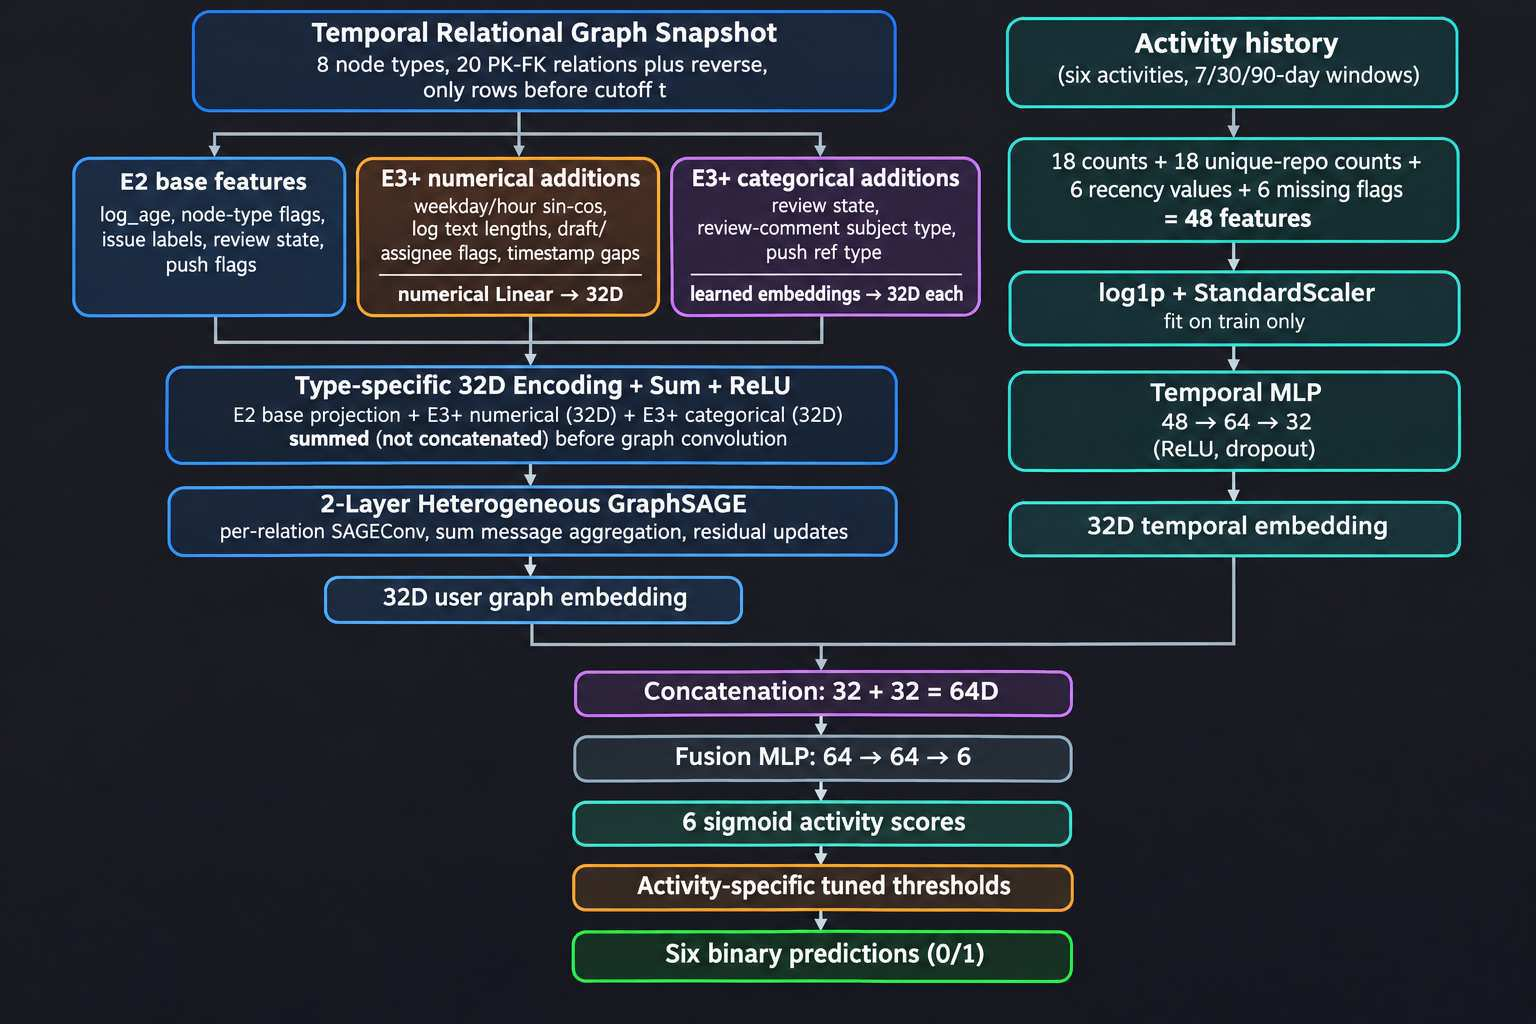

In [113]:
"""E3+ column encoding ablations (only features actually used).

`cyclical_only`: four sin/cos day/hour features for every node type.
`cyclical_repo_activity`: cyclical + 7/30-day six-type repository counts.
`cyclical_workflow_flags`: cyclical + PR cross-repo/draft, and issue-assignee flags.
No categorical embeddings, text lengths, numbering, positional or observation delay.
E2 original node features remain in graph[node_type].x; E3 temporal MLP remains.
"""
ROW_TIME = dict(TABLE_SPECS)  # use the existing graph schema; no duplicate definitions

def _as_flag(df, field):
    return df[field].fillna(False).astype("boolean").fillna(False).astype("float32").to_numpy()

def _as_present(df, field):
    return df[field].notna().astype("float32").to_numpy()

def _numeric_columns(df, node_type, row_time_col, variant=None):
    variant = E3PLUS_VARIANT if variant is None else variant
    assert variant in ALLOWED_E3PLUS_VARIANTS, variant
    times = pd.to_datetime(df[row_time_col], errors="coerce")
    dow = times.dt.dayofweek.fillna(0).to_numpy(dtype=np.float64)
    hour = times.dt.hour.fillna(0).to_numpy(dtype=np.float64)
    columns = OrderedDict([
        ("dow_sin", np.sin(2*np.pi*dow/7).astype("float32")),
        ("dow_cos", np.cos(2*np.pi*dow/7).astype("float32")),
        ("hour_sin", np.sin(2*np.pi*hour/24).astype("float32")),
        ("hour_cos", np.cos(2*np.pi*hour/24).astype("float32")),
    ])
    if variant == "cyclical_workflow_flags":
        if node_type == "prs":
            columns["is_cross_repo"] = _as_flag(df, "is_cross_repo")
            columns["is_draft"] = _as_flag(df, "draft")
        elif node_type == "issues":
            columns["has_assignee"] = _as_present(df, "assignee_id")
    return columns

def build_column_feature_cache(tables, variant=None):
    variant = E3PLUS_VARIANT if variant is None else variant
    assert variant in ALLOWED_E3PLUS_VARIANTS, variant
    cache = {"num":{}, "cat":{}, "num_names":{}, "cat_names":{},
             "cat_sizes":{}, "variant":variant}
    for node_type, (pk, row_time_col) in ROW_TIME.items():
        df = tables[node_type].sort_values(pk).reset_index(drop=True)
        ids = df[pk].to_numpy(dtype=np.int64)
        if not np.array_equal(ids, np.arange(len(df))):
            raise ValueError(f"{node_type}: expected PK IDs 0..N-1; cannot index feature cache")
        columns = _numeric_columns(df, node_type, row_time_col, variant)
        array = np.column_stack(list(columns.values())).astype(np.float32)
        if array.shape[0] != len(df) or not np.isfinite(array).all():
            raise ValueError(f"{node_type}: malformed encoding")
        cache["num"][node_type] = torch.from_numpy(array)
        cache["num_names"][node_type] = list(columns)
        cache["cat"][node_type] = torch.empty((len(df), 0), dtype=torch.long)
        cache["cat_names"][node_type] = []
        cache["cat_sizes"][node_type] = {}
    return cache

def enhance_sampled_batch(batch, cache):
    """Call after create_week_loader() yields a CPU batch, BEFORE batch.to(device).

    Original Step 7 node features remain first, then numerical extras are appended.
    PK alignment uses row_id stored on the existing HeteroData nodes.
    """
    for nt in batch.node_types:
        if 'row_id' not in batch[nt]:
            raise KeyError(f'{nt}: batch has no row_id; check Step 6 graph builder')
        ids = batch[nt].row_id.to(dtype=torch.long, device='cpu')
        if ids.numel() and (ids.min() < 0 or ids.max() >= len(cache['num'][nt])):
            raise IndexError(f'{nt}: sampled row_id outside global table')
        original_x = batch[nt].x.float()
        extras = cache['num'][nt].index_select(0, ids)
        if original_x.shape[0] != extras.shape[0]:
            raise ValueError(f'{nt}: feature order/length mismatch')
        batch[nt].x = torch.cat([original_x, extras], dim=-1)
        batch[nt].cat = cache['cat'][nt].index_select(0, ids)
    return batch


class ColumnEnhancedHybrid(nn.Module):
    """E3 backbone + numerical column projections + per-column category embeddings.

    Extra embeddings are zero-initialized, so at initialization this model
    computes the SAME outputs as the supplied pretrained E3 (in eval mode).
    """

    def __init__(self, pretrained_hybrid, cache):
        super().__init__()
        self.backbone = copy.deepcopy(pretrained_hybrid)
        self.base_dims = {}
        self.extra_dims = {}
        self.cat_names = {}
        self.num_projections = nn.ModuleDict()
        self.cat_embeddings = nn.ModuleDict()
        for nt, encoder in self.backbone.encoders.items():
            base = int(encoder.in_features)
            hid = int(encoder.out_features)
            extra = len(cache['num_names'][nt])
            self.base_dims[nt] = base
            self.extra_dims[nt] = extra
            self.cat_names[nt] = cache['cat_names'][nt]
            layer = nn.Linear(extra, hid, bias=False)
            nn.init.zeros_(layer.weight)
            self.num_projections[nt] = layer
            emb = nn.ModuleDict()
            for name, cardinality in cache['cat_sizes'][nt].items():
                table = nn.Embedding(cardinality, hid)
                nn.init.zeros_(table.weight)
                emb[name] = table
            self.cat_embeddings[nt] = emb

    def forward(self, batch, temporal_x):
        h = {}
        for nt, encoder in self.backbone.encoders.items():
            x = batch[nt].x.float()
            base_dim = self.base_dims[nt]
            extra_dim = self.extra_dims[nt]
            if x.shape[1] != base_dim + extra_dim:
                raise ValueError(f'{nt}: expected {base_dim}+{extra_dim} features, got {x.shape[1]}')
            z = encoder(x[:, :base_dim])
            z = z + self.num_projections[nt](x[:, base_dim:])
            if self.cat_names[nt]:
                cat = batch[nt].cat.long()
                if cat.shape[1] != len(self.cat_names[nt]):
                    raise ValueError(f'{nt}: categorical columns mismatch')
                for i, name in enumerate(self.cat_names[nt]):
                    z = z + self.cat_embeddings[nt][name](cat[:, i])
            h[nt] = F.relu(z)

        for conv in self.backbone.convs:
            messages = conv(h, batch.edge_index_dict)
            h = {nt: (F.relu(x + messages[nt]) if nt in messages else x)
                 for nt, x in h.items()}

        n = batch['users'].batch_size
        user_rep = h['users'][:n]
        temporal_rep = self.backbone.temporal_encoder(temporal_x)
        return self.backbone.head(torch.cat([user_rep, temporal_rep], dim=-1))


In [114]:
# Build a NEW cache for this variant, independent from previous variants.
REPO_ACTIVITY_TYPES = ["pr", "issue", "issue_comment", "review", "review_comment", "push"]
REPO_ACTIVITY_WINDOWS = (7, 30)
REPO_FEATURE_NAMES = [
    f"{activity}_count_{days}d"
    for activity in REPO_ACTIVITY_TYPES for days in REPO_ACTIVITY_WINDOWS
]

def create_variant_feature_cache(variant):
    cache = build_column_feature_cache(graph_tables, variant=variant)
    if variant == "cyclical_repo_activity":
        cache["num"]["repos"] = torch.cat([
            cache["num"]["repos"],
            torch.zeros((len(graph_tables["repos"]), len(REPO_FEATURE_NAMES)), dtype=torch.float32)
        ], dim=1)
        cache["num_names"]["repos"].extend(REPO_FEATURE_NAMES)
        cache["repo_activity_by_time"] = {}
    return cache

feature_cache = create_variant_feature_cache(E3PLUS_VARIANT)

# Consolidated schema checks for all variants (no variant-specific assertion).
cyclic = {"dow_sin", "dow_cos", "hour_sin", "hour_cos"}
expected_extra = {"prs":{"is_cross_repo", "is_draft"},
                  "issues":{"has_assignee"}}
for nt in graph_tables:
    names = feature_cache["num_names"][nt]
    cats = feature_cache["cat_names"][nt]
    expected = cyclic.copy()
    if E3PLUS_VARIANT == "cyclical_workflow_flags": expected |= expected_extra.get(nt, set())
    if E3PLUS_VARIANT == "cyclical_repo_activity" and nt == "repos":
        expected |= set(REPO_FEATURE_NAMES)
    assert set(names) == expected, (E3PLUS_VARIANT, nt, names, expected)
    assert len(names) == len(expected) and not cats, (nt, cats)
    assert feature_cache["num"][nt].shape[0] == len(graph_tables[nt])
    print(f"{nt:16s} numeric={names} | categorical={cats}")
print("✓ Feature cache matches the chosen E3+ variant")

users            numeric=['dow_sin', 'dow_cos', 'hour_sin', 'hour_cos'] | categorical=[]
repos            numeric=['dow_sin', 'dow_cos', 'hour_sin', 'hour_cos'] | categorical=[]
prs              numeric=['dow_sin', 'dow_cos', 'hour_sin', 'hour_cos', 'is_cross_repo', 'is_draft'] | categorical=[]
issues           numeric=['dow_sin', 'dow_cos', 'hour_sin', 'hour_cos', 'has_assignee'] | categorical=[]
issue_comments   numeric=['dow_sin', 'dow_cos', 'hour_sin', 'hour_cos'] | categorical=[]
reviews          numeric=['dow_sin', 'dow_cos', 'hour_sin', 'hour_cos'] | categorical=[]
review_comments  numeric=['dow_sin', 'dow_cos', 'hour_sin', 'hour_cos'] | categorical=[]
pushes           numeric=['dow_sin', 'dow_cos', 'hour_sin', 'hour_cos'] | categorical=[]
✓ Feature cache matches the chosen E3+ variant


In [115]:
# Repo-activity aggregates must be recalculated at every cutoff.
# The cache is keyed by original row ID, not by sampled PyG batch index.
def set_repo_activity_features(t, cache=None, variant=None):
    cache = feature_cache if cache is None else cache
    variant = cache["variant"] if variant is None else variant
    if variant != "cyclical_repo_activity":
        return
    t = pd.Timestamp(t)
    memo = cache["repo_activity_by_time"]
    if t not in memo:
        n_repos = len(graph_tables["repos"])
        values = np.zeros((n_repos, len(REPO_FEATURE_NAMES)), dtype=np.float32)
        for activity in REPO_ACTIVITY_TYPES:
            cfg = activity_configs[activity]
            observed = get_activity_window(cfg, t, days=30)
            event_col = cfg["activity_time_col"]
            if "repo_id" not in observed.columns:
                raise KeyError(f"{activity}: missing repo_id")
            observed = observed.loc[
                observed["repo_id"].notna(), ["repo_id", event_col]
            ]
            for days in REPO_ACTIVITY_WINDOWS:
                history = observed.loc[
                    observed[event_col] >= t - pd.Timedelta(days=days)
                ]
                counts = history.groupby("repo_id").size()
                if len(counts) == 0:
                    continue
                ids = pd.to_numeric(counts.index, errors="coerce").to_numpy(dtype=np.int64)
                valid = (ids >= 0) & (ids < n_repos)
                j = REPO_FEATURE_NAMES.index(f"{activity}_count_{days}d")
                values[ids[valid], j] = np.log1p(counts.to_numpy()[valid]).astype(np.float32)
        memo[t] = torch.from_numpy(values)
    cache["num"]["repos"][:, -len(REPO_FEATURE_NAMES):] = memo[t]


In [116]:
# Snapshot and cache alignment check, run BEFORE training each variant.
assert all(not feature_cache["cat_names"][nt] for nt in graph_tables)
assert all(torch.isfinite(x).all() for x in feature_cache["num"].values())
for nt in graph_tables:
    pk = ROW_TIME[nt][0]
    ids = graph_tables[nt][pk].to_numpy(dtype=np.int64)
    assert np.array_equal(np.sort(ids), np.arange(len(ids))), (nt, "row IDs must be 0..N-1")
print("✓ Node ID alignment, feature dimensions, and numeric finiteness passed")

✓ Node ID alignment, feature dimensions, and numeric finiteness passed


In [117]:
# 9A.2 — Initialize model

torch.manual_seed(42)

enhanced_model = ColumnEnhancedHybrid(
    pretrained_hybrid=hybrid_model,
    cache=feature_cache
).to(device)

# Unfreeze the entire E3 backbone + new column encoders
for param in enhanced_model.parameters():
    param.requires_grad_(True)

enhanced_optimizer = torch.optim.AdamW(
    enhanced_model.parameters(),
    lr=2e-4,
    weight_decay=1e-4
)

enhanced_criterion = hybrid_criterion

print(
    "E3+ trainable parameters:",
    sum(
        p.numel()
        for p in enhanced_model.parameters()
        if p.requires_grad
    )
)

print(
    "E3+ numerical features:",
    {
        nt: len(feature_cache["num_names"][nt])
        for nt in feature_cache["num_names"]
    }
)

E3+ trainable parameters: 178086
E3+ numerical features: {'users': 4, 'repos': 4, 'prs': 6, 'issues': 5, 'issue_comments': 4, 'reviews': 4, 'review_comments': 4, 'pushes': 4}


In [118]:
# Sanity check init

hybrid_model.eval()
enhanced_model.eval()

t, week = next(
    iter(val_df.groupby("prediction_time", sort=True))
)

set_repo_activity_features(t)

loader, graph, _ = create_week_loader(
    t, week, shuffle=False, batch_size=32
)

batch = next(iter(loader))
n = batch["users"].batch_size

indices = (
    batch["users"].sample_index[:n]
    .cpu().numpy()
)

temporal_x = torch.as_tensor(
    temp_val.loc[indices].to_numpy(dtype=np.float32),
    device=device
)

batch_original = copy.deepcopy(batch).to(device)
batch_enhanced = enhance_sampled_batch(
    batch, feature_cache
).to(device)

with torch.no_grad():
    old_logits = hybrid_model(
        batch_original, temporal_x
    )
    new_logits = enhanced_model(
        batch_enhanced, temporal_x
    )

difference = (
    old_logits - new_logits
).abs().max().item()

print("Maximum difference:", difference)

assert torch.allclose(
    old_logits, new_logits,
    atol=1e-5
)

del loader, graph

Maximum difference: 4.76837158203125e-07


In [119]:
# 9A.3 Train enhanced hybrid model

ENHANCED_EPOCHS = 3

for epoch in range(ENHANCED_EPOCHS):

    enhanced_model.train()

    total_loss = 0.0
    steps = 0

    for t, week in train_df.groupby(
        "prediction_time",
        sort=True
    ):
        # New: correct historical repository features for this week
        set_repo_activity_features(t)

        loader, graph, available = create_week_loader(
            t, week,
            shuffle=True,
            batch_size=64
        )

        if loader is None:
            continue

        for batch in loader:

            n = batch["users"].batch_size

            indices = (
                batch["users"]
                .sample_index[:n]
                .cpu()
                .numpy()
            )

            temporal_x = torch.as_tensor(
                temp_train.loc[
                    indices
                ].to_numpy(dtype=np.float32),
                device=device
            )

            # Append richer column encodings
            batch = enhance_sampled_batch(
                batch, feature_cache
            ).to(device)

            logits = enhanced_model(
                batch, temporal_x
            )

            labels = batch["users"].y[:n].float()

            loss = enhanced_criterion(
                logits, labels
            )

            enhanced_optimizer.zero_grad()

            loss.backward()

            torch.nn.utils.clip_grad_norm_(
                enhanced_model.parameters(),
                max_norm=1.0
            )

            enhanced_optimizer.step()

            total_loss += loss.item()
            steps += 1

        del loader, graph

    print(
        f"Epoch {epoch + 1}: "
        f"Loss = {total_loss / max(steps, 1):.4f}"
    )

Epoch 1: Loss = 0.3910
Epoch 2: Loss = 0.3921
Epoch 3: Loss = 0.3904


### Threshold calibration on September 20 (diagnostic only)

In [120]:
# Reusable E3+ inference on ANY cutoff (tuning, benchmark, or final test).
# Uses the frozen scaler learned on train_df; does NOT fit any parameters.
# Unavailable graph users remain all-zero, consistent with prior evaluations.

def predict_e3plus(week_df):

    # Transform features using existing training scaler
    temp_raw = prepare_temporal_features(
        week_df,
        feature_cols
    )

    temp_features = pd.DataFrame(
        scaler.transform(temp_raw).astype("float32"),
        index=week_df.index,
        columns=temp_raw.columns
    )

    probabilities = pd.DataFrame(
        0.0,
        index=week_df.index,
        columns=target_cols
    )

    enhanced_model.eval()

    with torch.no_grad():

        for t, week in week_df.groupby(
            "prediction_time",
            sort=True
        ):
            set_repo_activity_features(t)

            loader, graph, available = create_week_loader(
                t,
                week,
                shuffle=False,
                batch_size=64
            )

            print(
                t,
                "available users:",
                available,
                "/",
                len(week)
            )

            if loader is None:
                continue

            for batch in loader:

                n = batch["users"].batch_size

                indices = (
                    batch["users"]
                    .sample_index[:n]
                    .cpu()
                    .numpy()
                )

                temporal_x = torch.as_tensor(
                    temp_features.loc[
                        indices
                    ].to_numpy(dtype=np.float32),
                    device=device
                )

                batch = enhance_sampled_batch(
                    batch,
                    feature_cache
                ).to(device)

                logits = enhanced_model(
                    batch,
                    temporal_x
                )

                probs = torch.sigmoid(
                    logits
                ).cpu().numpy()

                probabilities.loc[
                    indices,
                    target_cols
                ] = probs

            del loader, graph

    return probabilities

In [121]:
# Threshold calibration is performed on exactly one held-out, labeled week.
# This E3+ checkpoint was trained only on the preceding train_df weeks.

# Generate predicted probabilities for threshold tuning
tuning_df = val_df.copy()

tuning_probs = predict_e3plus(tuning_df)

tuning_y = tuning_df[target_cols].astype(int)

# Generate binary prediction 0/1 based on thresh=0.5 (as a baseline comparison)
val_probs_enhanced = tuning_probs.copy()

val_preds_enhanced = (tuning_probs >= 0.5).astype(int)


print("Tuning week:", tuning_df["prediction_time"].iloc[0])

display(tuning_probs.head())

2026-09-19 16:00:00 available users: 7597 / 7745
Tuning week: 2026-09-19 16:00:00


,open_pr,open_issue,issue_comment,pr_review,pr_review_comment,push
38725,0.501861,0.101187,0.163864,0.079855,0.053909,0.740697
38726,0.829864,0.845514,0.833806,0.730049,0.588664,0.861510
38727,0.202163,0.053451,0.077919,0.043081,0.031550,0.253268
38728,0.953973,0.983711,0.963773,0.344681,0.223041,0.982167
38729,0.929949,0.367924,0.827341,0.295802,0.194098,0.973787


In [122]:
best_thresholds = tune_thresholds(tuning_y, tuning_probs)
threshold_grid = np.linspace(0.05, 0.95, 91)
tuning_rows = []
for activity in target_cols:
    y = tuning_y[activity].to_numpy(dtype=int)
    p = tuning_probs[activity].to_numpy(dtype=float)
    th = best_thresholds[activity]
    tuning_rows.append({
        "Activity":activity, "Best Threshold":th,
        "F1 (0.5)":f1_score(y, p >= 0.5, zero_division=0),
        "Best Tuning F1":f1_score(y, p >= th, zero_division=0)
    })
threshold_tuning_results = pd.DataFrame(tuning_rows).set_index("Activity")
assert set(best_thresholds) == set(target_cols)
display(threshold_tuning_results.round(4))

,Best Threshold,F1 (0.5),Best Tuning F1
Activity,,,
open_pr,0.77,0.3309,0.4149
open_issue,0.80,0.3516,0.4838
issue_comment,0.79,0.2970,0.4301
pr_review,0.82,0.3393,0.4373
pr_review_comment,0.82,0.3145,0.4286
push,0.43,0.6893,0.6948


In [123]:
# Add E3 model+ (threshold tuned) to evaluation df

tuned_thresholds = pd.Series(best_thresholds).reindex(target_cols)
val_preds_tuned_enhanced = tuning_probs.ge(tuned_thresholds, axis="columns").astype(int)

enhanced_results_tuned = evaluate_by_week(
    val_preds_tuned_enhanced,
    "E3+ Column Encoding (Tuned)"
)

# Replace previous E3+ Column Encoding (Tuned) rows if this cell is rerun
official_results = pd.concat(
    [
        official_results[
            official_results["Model"] != "E3+ Column Encoding (Tuned)"
        ],
        enhanced_results_tuned
    ],
    ignore_index=True
)

In [124]:
# Add E3 model+ (NOT threshold tuned) to evaluation df

enhanced_results = evaluate_by_week(
    val_preds_enhanced,
    "E3+ Column Encoding (NOT Tuned)"
)

# Replace previous E3+ Column Encoding (NOT Tuned) rows if this cell is rerun
official_results = pd.concat(
    [
        official_results[
            official_results["Model"] != "E3+ Column Encoding (NOT Tuned)"
        ],
        enhanced_results
    ],
    ignore_index=True
)

In [125]:
official_results

,Model,Week,Macro-F1,Micro-F1,Score
0,E0 — Copy Last Week,2026-09-19 16:00:00,0.430261,0.514606,0.472433
1,E1 — LightGBM,2026-09-19 16:00:00,0.447918,0.490368,0.469143
2,E2 Temporal HetGNN,2026-09-19 16:00:00,0.370147,0.451231,0.410689
3,E3 Hybrid HetGNN+Temporal,2026-09-19 16:00:00,0.390354,0.477623,0.433988
4,E3 Hybrid HetGNN (Tuned),2026-09-19 16:00:00,0.482999,0.597977,0.540488
5,E3+ Column Encoding (Tuned),2026-09-19 16:00:00,0.481571,0.591200,0.536386
6,E3+ Column Encoding (NOT Tuned),2026-09-19 16:00:00,0.387086,0.470570,0.428828


In [126]:
model_comparison = (
    official_results
    .groupby("Model")[
        ["Macro-F1", "Micro-F1", "Score"]
    ]
    .mean()
    .sort_values("Score", ascending=False)
)

model_comparison.round(4)

,Macro-F1,Micro-F1,Score
Model,,,
E3 Hybrid HetGNN (Tuned),0.4830,0.5980,0.5405
E3+ Column Encoding (Tuned),0.4816,0.5912,0.5364
E0 — Copy Last Week,0.4303,0.5146,0.4724
E1 — LightGBM,0.4479,0.4904,0.4691
E3 Hybrid HetGNN+Temporal,0.3904,0.4776,0.4340
E3+ Column Encoding (NOT Tuned),0.3871,0.4706,0.4288
E2 Temporal HetGNN,0.3701,0.4512,0.4107


# Step 12 — Four-week benchmark, ablation comparison, and permanent result archive

The evaluation below is **held out** relative to the Sep 20 threshold-calibration week. Running Step 12 for another variant creates a NEW, versioned CSV and E3+ checkpoint rather than overwriting the earlier variant. Never modify global `val_df` to score benchmark weeks.

In [127]:
assert RUN_MODE == "benchmark"
assert benchmark_df["prediction_time"].nunique() == 4
assert benchmark_df["prediction_time"].min() > tuning_t
benchmark_probs = predict_e3plus(benchmark_df)
assert benchmark_probs.index.equals(benchmark_df.index)
assert np.isfinite(benchmark_probs.to_numpy()).all()
print("Held-out benchmark cutoffs:", benchmark_df["prediction_time"].unique())

2026-09-26 16:00:00 available users: 7625 / 7745
2026-10-03 16:00:00 available users: 7655 / 7745
2026-10-10 16:00:00 available users: 7675 / 7745
2026-10-17 16:00:00 available users: 7706 / 7745
Held-out benchmark cutoffs: <DatetimeArray>
['2026-09-26 16:00:00', '2026-10-03 16:00:00', '2026-10-10 16:00:00',
 '2026-10-17 16:00:00']
Length: 4, dtype: datetime64[ns]


In [128]:
# ============================================================
# MULTI-WEEK EVALUATION: E0, E1, E2, E3, E3+
# ============================================================
# Train: Aug 16 – Sep 13
# Tune:  Sep 20
# Test:  Sep 27, Oct 4, Oct 11, Oct 18
#
# All models are frozen during evaluation.
# E3 and E3+ each use thresholds calibrated independently on Sep 20.

assert RUN_MODE == "benchmark"
assert benchmark_df["prediction_time"].nunique() == 4
assert set(lgb_models) == set(target_cols)

# ------------------------------------------------------------
# E0 — Copy Last Week
# ------------------------------------------------------------
e0_preds = pd.DataFrame(index=benchmark_df.index)

for target, activity in zip(target_cols, activity_names):
    e0_preds[target] = (
        benchmark_df[f"{activity}_count_7d"] > 0
    ).astype(int)


# ------------------------------------------------------------
# E1 — LightGBM
# ------------------------------------------------------------
X_test_weeks = benchmark_df[feature_cols]

e1_probs = pd.DataFrame(
    index=benchmark_df.index,
    columns=target_cols,
    dtype=float
)

for target in target_cols:
    e1_probs[target] = (
        lgb_models[target].predict_proba(
            X_test_weeks
        )[:, 1]
    )

e1_preds = (e1_probs >= 0.5).astype(int)


# ------------------------------------------------------------
# E2 / E3 — Graph inference
# ------------------------------------------------------------
# Reuse the same sampled graph batches for both models.
# The temporal scaler was fitted on train_df only.

temporal_raw = prepare_temporal_features(
    benchmark_df,
    feature_cols
)

temporal_test = pd.DataFrame(
    scaler.transform(temporal_raw).astype("float32"),
    index=benchmark_df.index,
    columns=temporal_raw.columns
)

e2_probs = pd.DataFrame(
    0.0,
    index=benchmark_df.index,
    columns=target_cols
)

e3_probs = pd.DataFrame(
    0.0,
    index=benchmark_df.index,
    columns=target_cols
)

gnn_model.eval()
hybrid_model.eval()

torch.manual_seed(42)

with torch.no_grad():

    for t, week in benchmark_df.groupby(
        "prediction_time",
        sort=True
    ):

        loader, graph, available = create_week_loader(
            t,
            week,
            shuffle=False,
            batch_size=32
        )

        print(
            f"Evaluating {t} | "
            f"Graph users: {available}/{len(week)}"
        )

        if loader is None:
            continue

        for batch in loader:

            n = batch["users"].batch_size

            indices = (
                batch["users"]
                .sample_index[:n]
                .cpu()
                .numpy()
            )

            # E3-specific historical activity features
            temporal_x = torch.as_tensor(
                temporal_test.loc[
                    indices
                ].to_numpy(dtype=np.float32),
                device=device
            )

            batch = batch.to(device)

            # E2: Snapshot-based HetGNN
            logits_e2 = gnn_model(batch)[:n]

            # E3: Hybrid HetGNN + temporal MLP
            logits_e3 = hybrid_model(
                batch,
                temporal_x
            )

            e2_probs.loc[indices, target_cols] = (
                torch.sigmoid(logits_e2)
                .cpu()
                .numpy()
            )

            e3_probs.loc[indices, target_cols] = (
                torch.sigmoid(logits_e3)
                .cpu()
                .numpy()
            )

        del loader, graph

e2_preds = (e2_probs >= 0.5).astype(int)
e3_preds = (e3_probs >= 0.5).astype(int)

# E3 tuned thresholds from Sep 20 only
e3_threshold_series = pd.Series(
    e3_best_thresholds
).reindex(target_cols)

assert e3_threshold_series.notna().all()

e3_preds_tuned = e3_probs.ge(
    e3_threshold_series,
    axis="columns"
).astype(int)

# ------------------------------------------------------------
# E3+ — Column-Enhanced Hybrid HetGNN
# ------------------------------------------------------------
# benchmark_probs was generated in Cell 114.
# Do NOT retrain or optimize thresholds on these test weeks.

e3plus_preds_05 = (
    benchmark_probs >= 0.5
).astype(int)

threshold_series = pd.Series(
    best_thresholds
).reindex(target_cols)

assert threshold_series.notna().all()

e3plus_preds_tuned = benchmark_probs.ge(
    threshold_series,
    axis="columns"
).astype(int)


# ------------------------------------------------------------
# Collect all models
# ------------------------------------------------------------
current_benchmark_predictions = {
    "E0 — Copy Last Week": e0_preds,
    "E1 — LightGBM": e1_preds,
    "E2 — Snapshot HetGNN": e2_preds,
    "E3 — Hybrid HetGNN": e3_preds,
    "E3 — Hybrid HetGNN (Tuned)": e3_preds_tuned,
    "E3+ — Column Enhanced (0.5)": e3plus_preds_05,
    "E3+ — Column Enhanced (Tuned)": e3plus_preds_tuned,
}

print("Predictions generated for all models.")

Evaluating 2026-09-26 16:00:00 | Graph users: 7625/7745
Evaluating 2026-10-03 16:00:00 | Graph users: 7655/7745
Evaluating 2026-10-10 16:00:00 | Graph users: 7675/7745
Evaluating 2026-10-17 16:00:00 | Graph users: 7706/7745
Predictions generated for all models.


In [129]:
# ============================================================
# MULTI-WEEK OFFICIAL EVALUATION: E0, E1, E2, E3, E3+
# ============================================================

current_benchmark_results = []

for t, week in benchmark_df.groupby(
    "prediction_time",
    sort=True
):

    # Convert UTC cutoff to Taiwan date for display
    week_label = (
        pd.Timestamp(t)
        .tz_localize("UTC")
        .tz_convert("Asia/Taipei")
        .strftime("%Y-%m-%d")
    )

    # Ground truth
    truth = week[target_cols].copy()

    truth.insert(
        0,
        "UserID",
        week["github_user_id"].to_numpy()
    )

    truth = truth.reset_index(drop=True)

    # Evaluate every model on the same week
    for model_name, predictions in current_benchmark_predictions.items():

        pred = predictions.loc[
            week.index, target_cols
        ].copy()

        pred.insert(
            0,
            "UserID",
            week["github_user_id"].to_numpy()
        )

        pred = pred.reset_index(drop=True)

        # Official assignment evaluator
        result = official_scores(pred, truth)

        current_benchmark_results.append({
            "Week": week_label,
            "Model": model_name,
            "Macro-F1": result["macro_f1"],
            "Micro-F1": result["micro_f1"],
            "Score": result["score"]
        })

current_benchmark_results = pd.DataFrame(current_benchmark_results)

current_benchmark_results["Variant"] = E3PLUS_VARIANT
display(current_benchmark_results.round(4))

,Week,Model,Macro-F1,Micro-F1,Score,Variant
0,2026-09-27,E0 — Copy Last Week,0.4235,0.5490,0.4862,cyclical_workflow_flags
1,2026-09-27,E1 — LightGBM,0.3862,0.4129,0.3996,cyclical_workflow_flags
2,2026-09-27,E2 — Snapshot HetGNN,0.4213,0.4931,0.4572,cyclical_workflow_flags
3,2026-09-27,E3 — Hybrid HetGNN,0.4426,0.5168,0.4797,cyclical_workflow_flags
4,2026-09-27,E3 — Hybrid HetGNN (Tuned),0.4636,0.5975,0.5305,cyclical_workflow_flags
5,2026-09-27,E3+ — Column Enhanced (0.5),0.4406,0.5104,0.4755,cyclical_workflow_flags
6,2026-09-27,E3+ — Column Enhanced (Tuned),0.4807,0.6013,0.5410,cyclical_workflow_flags
7,2026-10-04,E0 — Copy Last Week,0.4436,0.5487,0.4962,cyclical_workflow_flags
8,2026-10-04,E1 — LightGBM,0.4312,0.4685,0.4498,cyclical_workflow_flags
9,2026-10-04,E2 — Snapshot HetGNN,0.3418,0.4210,0.3814,cyclical_workflow_flags


In [130]:
# Render comparison before saving; these are averages of four weekly scores,
# not pooled F1. Each variant gets a separate saved benchmark run.
current_benchmark_summary = (current_benchmark_results.groupby("Model")
    [["Macro-F1", "Micro-F1", "Score"]].mean().sort_values("Score", ascending=False))
current_benchmark_weekly = current_benchmark_results.pivot(
    index="Week", columns="Model", values="Score")
display(current_benchmark_summary.round(4))
display(current_benchmark_weekly.round(4))

,Macro-F1,Micro-F1,Score
Model,,,
E3+ — Column Enhanced (Tuned),0.4528,0.5679,0.5104
E3 — Hybrid HetGNN (Tuned),0.4487,0.5715,0.5101
E0 — Copy Last Week,0.4123,0.5275,0.4699
E3 — Hybrid HetGNN,0.3664,0.4492,0.4078
E1 — LightGBM,0.3979,0.4171,0.4075
E3+ — Column Enhanced (0.5),0.3639,0.4419,0.4029
E2 — Snapshot HetGNN,0.3429,0.4199,0.3814


Model,E0 — Copy Last Week,E1 — LightGBM,E2 — Snapshot HetGNN,E3 — Hybrid HetGNN,E3 — Hybrid HetGNN (Tuned),E3+ — Column Enhanced (0.5),E3+ — Column Enhanced (Tuned)
Week,,,,,,,
2026-09-27,0.4862,0.3996,0.4572,0.4797,0.5305,0.4755,0.5410
2026-10-04,0.4962,0.4498,0.3814,0.4032,0.5199,0.3976,0.5212
2026-10-11,0.4593,0.4049,0.3563,0.3818,0.5037,0.3786,0.5005
2026-10-18,0.4380,0.3758,0.3308,0.3666,0.4863,0.3600,0.4787


In [131]:
# Archive outputs PER VARIANT and PER RUN, without overwriting prior results.
import json
BENCHMARK_ARCHIVE_DIR = Path("assignment2/benchmark_runs")
BENCHMARK_ARCHIVE_DIR.mkdir(parents=True, exist_ok=True)
BENCHMARK_RUN_ID = pd.Timestamp.utcnow().strftime("%Y%m%dT%H%M%S%fZ")
BENCHMARK_PREFIX = BENCHMARK_ARCHIVE_DIR / f"benchmark_{E3PLUS_VARIANT}_{BENCHMARK_RUN_ID}"

current_benchmark_results = current_benchmark_results.copy()
current_benchmark_results["RunID"] = BENCHMARK_RUN_ID
current_benchmark_results.to_csv(str(BENCHMARK_PREFIX) + ".csv", index=False)
torch.save(enhanced_model.state_dict(), str(BENCHMARK_PREFIX) + "_e3plus.pt")
joblib.dump({
    "variant": E3PLUS_VARIANT, "run_id": BENCHMARK_RUN_ID,
    "e3plus_thresholds": best_thresholds, "e3_thresholds": e3_best_thresholds,
    "train_cutoffs": [str(v) for v in train_df["prediction_time"].unique()],
    "threshold_tune_cutoff": str(tuning_t),
    "benchmark_cutoffs": [str(v) for v in benchmark_df["prediction_time"].unique()],
    "feature_cols": feature_cols,
    "column_feature_names": feature_cache["num_names"],
}, str(BENCHMARK_PREFIX) + "_config.joblib")
print("Archived CSV:", str(BENCHMARK_PREFIX) + ".csv")
print("Archived weights:", str(BENCHMARK_PREFIX) + "_e3plus.pt")

Archived CSV: assignment2/benchmark_runs/benchmark_cyclical_workflow_flags_20261117T212056073141Z.csv
Archived weights: assignment2/benchmark_runs/benchmark_cyclical_workflow_flags_20261117T212056073141Z_e3plus.pt


### Snapshot of benchmark results already stored in the uploaded notebook

In [132]:
# Load ALL newly archived experiments without overwriting any variant.
# Re-executing Step 11/12 adds a uniquely named file instead of changing prior files.
archived_files = sorted(BENCHMARK_ARCHIVE_DIR.glob("benchmark_*.csv"))
if archived_files:
    benchmark_history = pd.concat(
        [pd.read_csv(p) for p in archived_files], ignore_index=True)
    benchmark_history["Week"] = benchmark_history["Week"].astype(str)
    e3plus_history = benchmark_history.loc[
        benchmark_history["Model"].str.startswith("E3+")
    ]
    # Averages by distinct run first: never silently mix several runs of one variant.
    archived_variant_summary = (e3plus_history.groupby(["Variant", "RunID", "Model"])
        ["Score"].mean().unstack("Model"))
    display(archived_variant_summary.round(4))
else:
    benchmark_history = pd.DataFrame()
    print("No newly archived runs yet. Run Step 12 for each desired variant.")

,Model,E3+ — Column Enhanced (0.5),E3+ — Column Enhanced (Tuned)
Variant,RunID,,
cyclical_only,20261117T211141640320Z,0.4098,0.5061
cyclical_repo_activity,20261117T211623370998Z,0.4091,0.5099
cyclical_workflow_flags,20261117T212056073141Z,0.4029,0.5104


In [138]:
# ============================================================
# E3+ ABLATION — WEEKLY BENCHMARK COMPARISON
# ============================================================

e3plus_weekly = benchmark_history.loc[
    benchmark_history["Model"].isin([
        "E3+ — Column Enhanced (0.5)",
        "E3+ — Column Enhanced (Tuned)"
    ])
].copy()

# Keep each run separately (no overwriting)
archived_weekly_summary = e3plus_weekly.pivot_table(
    index=["Week", "Variant", "RunID"],
    columns="Model",
    values="Score",
    aggfunc="first"
)

archived_weekly_summary = (
    archived_weekly_summary
    .sort_index()
)

archived_weekly_summary.columns = [
    "E3+ (0.5)"
    if "(0.5)" in col
    else "E3+ (Tuned)"
    for col in archived_weekly_summary.columns
]

display(archived_weekly_summary.round(4))

E3+ (0.5)  \
Week       Variant                 RunID                               
2026-09-27 cyclical_only           20261117T211141640320Z     0.4823   
           cyclical_repo_activity  20261117T211623370998Z     0.4814   
           cyclical_workflow_flags 20261117T212056073141Z     0.4755   
2026-10-04 cyclical_only           20261117T211141640320Z     0.4048   
           cyclical_repo_activity  20261117T211623370998Z     0.4053   
           cyclical_workflow_flags 20261117T212056073141Z     0.3976   
2026-10-11 cyclical_only           20261117T211141640320Z     0.3846   
           cyclical_repo_activity  20261117T211623370998Z     0.3814   
           cyclical_workflow_flags 20261117T212056073141Z     0.3786   
2026-10-18 cyclical_only           20261117T211141640320Z     0.3676   
           cyclical_repo_activity  20261117T211623370998Z     0.3682   
           cyclical_workflow_flags 20261117T212056073141Z     0.3600   

                                                           E3+ (Tuned)  
Week       Variant                 RunID                                
2026-09-27 cyclical_only           20261117T211141640320Z       0.5416  
           cyclical_repo_activity  20261117T211623370998Z       0.5482  
           cyclical_workflow_flags 20261117T212056073141Z       0.5410  
2026-10-04 cyclical_only           20261117T211141640320Z       0.5104  
           cyclical_repo_activity  20261117T211623370998Z       0.5110  
           cyclical_workflow_flags 20261117T212056073141Z       0.5212  
2026-10-11 cyclical_only           20261117T211141640320Z       0.4923  
           cyclical_repo_activity  20261117T211623370998Z       0.4954  
           cyclical_workflow_flags 20261117T212056073141Z       0.5005  
2026-10-18 cyclical_only           20261117T211141640320Z       0.4803  
           cyclical_repo_activity  20261117T211623370998Z       0.4852  
           cyclical_workflow_flags 20261117T212056073141Z       0.4787

In [139]:
# ============================================================
# OVERALL BENCHMARK SUMMARY (ALL MODELS + E3+ VARIANTS)
# ============================================================

summary_source = benchmark_history.copy()

# Rename E3+ rows so each variant appears as its own model name
def expand_model_name(row):
    model = row["Model"]
    variant = row.get("Variant", None)

    if model == "E3+ — Column Enhanced (0.5)":
        return f"E3+ ({variant}, 0.5)"
    elif model == "E3+ — Column Enhanced (Tuned)":
        return f"E3+ ({variant}, tuned)"
    else:
        return model

summary_source["Model_Display"] = summary_source.apply(
    expand_model_name,
    axis=1
)

overall_model_summary = (
    summary_source
    .groupby("Model_Display")[["Macro-F1", "Micro-F1", "Score"]]
    .mean()
    .sort_values("Score", ascending=False)
)

display(overall_model_summary.round(4))

,Macro-F1,Micro-F1,Score
Model_Display,,,
"E3+ (cyclical_workflow_flags, tuned)",0.4528,0.5679,0.5104
E3 — Hybrid HetGNN (Tuned),0.4487,0.5715,0.5101
"E3+ (cyclical_repo_activity, tuned)",0.4538,0.5661,0.5099
"E3+ (cyclical_only, tuned)",0.4492,0.5630,0.5061
E0 — Copy Last Week,0.4123,0.5275,0.4699
"E3+ (cyclical_only, 0.5)",0.3703,0.4493,0.4098
"E3+ (cyclical_repo_activity, 0.5)",0.3711,0.4470,0.4091
E3 — Hybrid HetGNN,0.3664,0.4492,0.4078
E1 — LightGBM,0.3979,0.4171,0.4075


### Diagnostics: benchmark vs tuning

The official four-week benchmark scores above are separate from Step 10/11 *tuning-week diagnostics*. **Do not optimize thresholds using the four benchmark labels and then report the same four weeks as an untouched test.** Every archived run includes its own thresholds and feature configuration. For per-activity inspection use the next cell, which reads only the current benchmark predictions.

In [133]:
# Per-activity F1 on each held-out week for E3 and E3+; no stale tuning predictions.
activity_rows = []
for t, week in benchmark_df.groupby("prediction_time", sort=True):
    for model_name, pred in current_benchmark_predictions.items():
        for target in target_cols:
            activity_rows.append({
                "Week": pd.Timestamp(t).tz_localize("UTC").tz_convert("Asia/Taipei").strftime("%Y-%m-%d"),
                "Variant": E3PLUS_VARIANT, "Model": model_name, "Activity": target,
                "F1": f1_score(week[target].astype(int),
                               pred.loc[week.index,target].astype(int), zero_division=0)
            })
current_benchmark_activity_f1 = pd.DataFrame(activity_rows)
display(current_benchmark_activity_f1.head(16).round(4))

,Week,Variant,Model,Activity,F1
0,2026-09-27,cyclical_workflow_flags,E0 — Copy Last Week,open_pr,0.3839
1,2026-09-27,cyclical_workflow_flags,E0 — Copy Last Week,open_issue,0.3854
2,2026-09-27,cyclical_workflow_flags,E0 — Copy Last Week,issue_comment,0.3794
3,2026-09-27,cyclical_workflow_flags,E0 — Copy Last Week,pr_review,0.3612
4,2026-09-27,cyclical_workflow_flags,E0 — Copy Last Week,pr_review_comment,0.3590
5,2026-09-27,cyclical_workflow_flags,E0 — Copy Last Week,push,0.6720
6,2026-09-27,cyclical_workflow_flags,E1 — LightGBM,open_pr,0.3632
7,2026-09-27,cyclical_workflow_flags,E1 — LightGBM,open_issue,0.3723
8,2026-09-27,cyclical_workflow_flags,E1 — LightGBM,issue_comment,0.3919
9,2026-09-27,cyclical_workflow_flags,E1 — LightGBM,pr_review,0.4047


### Leakage and feature assertions (single audit section)

In [134]:
# Check snapshot observability using exactly the benchmark weeks.
for t in sorted(benchmark_df["prediction_time"].unique()):
    graph, snapshot = build_graph_snapshot(pd.Timestamp(t), graph_tables)
    for nt, (_, time_col) in TABLE_SPECS.items():
        assert snapshot[nt][time_col].notna().all(), (t, nt, "missing row time")
        assert (snapshot[nt][time_col] < t).all(), (t, nt, "future node")
    assert len(graph.edge_types) == 2 * len(FK_RELATIONS)
print("✓ All four benchmark graph snapshots obey cutoff availability")

assert benchmark_probs.columns.tolist() == target_cols
assert benchmark_probs.index.equals(benchmark_df.index)
assert np.isfinite(benchmark_probs.to_numpy()).all()
assert all(len(feature_cache["num_names"][nt]) == feature_cache["num"][nt].shape[1]
           for nt in graph_tables)
print("✓ Benchmark prediction alignment and E3+ feature dimensions passed")

✓ All four benchmark graph snapshots obey cutoff availability
✓ Benchmark prediction alignment and E3+ feature dimensions passed


# Step 13 — Choose the winning model and retrain independently for the Nov 22 submission

**No benchmark outputs are overwritten here.** This section chooses a model from the saved multi-week results, then trains **new model objects** on Aug 16–Oct 11, reserves Oct 18 for final threshold calibration, and predicts Nov 22. All original benchmark `train_df`, `val_df`, `scaler`, `gnn_model`, `hybrid_model`, `enhanced_model`, and archives remain unchanged.

In [140]:
# ============================================================
# 13.1 MODEL SELECTION — FROM ARCHIVED, FOUR-WEEK BENCHMARKS
# ============================================================
# Available models:
#
# Baselines:
# "E0"
# "E1"
# "E2"
# "E3_0.5"
# "E3_TUNED"
#
# E3+ Cyclical Time Only:
# "E3PLUS:cyclical_only"
# "E3PLUS_TUNED:cyclical_only"
#
# E3+ Cyclical + Repository Activity:
# "E3PLUS:cyclical_repo_activity"
# "E3PLUS_TUNED:cyclical_repo_activity"
#
# E3+ Cyclical + Workflow Flags:
# "E3PLUS:cyclical_workflow_flags"
# "E3PLUS_TUNED:cyclical_workflow_flags"
#
# "auto" selects the highest mean benchmark Score.

FINAL_MODEL_CHOICE = "E3PLUS_TUNED:cyclical_workflow_flags"
FINAL_TUNING_DATE = "2026-10-18"
FINAL_TUNE_T = taiwan_midnight_to_utc_naive(FINAL_TUNING_DATE)

# Only consider archived runs generated with the SAME benchmark setup.
model_to_key = {
    "E0 — Copy Last Week": "E0",
    "E1 — LightGBM": "E1",
    "E2 — Snapshot HetGNN": "E2",
    "E3 — Hybrid HetGNN": "E3_0.5",
    "E3 — Hybrid HetGNN (Tuned)": "E3_TUNED",
    "E3+ — Column Enhanced (0.5)": "E3PLUS_0.5",
    "E3+ — Column Enhanced (Tuned)": "E3PLUS_TUNED",
}

# Read the persisted benchmark history, not mutable in-memory result variables.
archive_files = sorted(Path("assignment2/benchmark_runs").glob("benchmark_*.csv"))
if not archive_files and FINAL_MODEL_CHOICE == "auto":
    raise RuntimeError("No archived benchmark runs. Execute Step 12 at least once before automatic model selection.")

selection_rows = []
for csv_path in archive_files:
    recorded = pd.read_csv(csv_path)
    expected_weeks = {"2026-09-27", "2026-10-04", "2026-10-11", "2026-10-18"}
    if not {"Week","Model","Score","Variant","RunID"}.issubset(recorded.columns):
        continue
    recorded["Week"] = recorded["Week"].astype(str).str.slice(0, 10)
    if set(recorded["Week"].unique()) != expected_weeks:
        continue
    for model_name, rows in recorded.groupby("Model", sort=False):
        base_key = model_to_key.get(model_name)
        if base_key is None or rows["Week"].nunique() != 4:
            continue
        variant = str(rows["Variant"].iloc[0])
        key = f"{base_key}:{variant}" if base_key.startswith("E3PLUS") else base_key
        selection_rows.append({
            "Choice": key,
            "Mean benchmark Score": rows["Score"].mean(),
            "RunID": str(rows["RunID"].iloc[0]),
            "Source CSV": str(csv_path),
        })

selection_scores = pd.DataFrame(selection_rows)
if not selection_scores.empty:
    # Use most recently archived run for each configuration. Avoid picking the
    # "luckiest" repeat of the same model based on future benchmark labels.
    selection_scores = (selection_scores.sort_values("RunID")
        .drop_duplicates("Choice", keep="last")
        .sort_values("Mean benchmark Score", ascending=False)
        .reset_index(drop=True))
    display(selection_scores[["Choice", "Mean benchmark Score", "RunID"]].round(4))

if FINAL_MODEL_CHOICE == "auto":
    if selection_scores.empty:
        raise RuntimeError("No valid four-week archived benchmark results found.")
    final_selected_model = str(selection_scores.iloc[0]["Choice"])
else:
    final_selected_model = FINAL_MODEL_CHOICE

valid_base_models = {"E0", "E1", "E2", "E3_0.5", "E3_TUNED"}
if final_selected_model not in valid_base_models:
    tokens = final_selected_model.split(":", 1)
    assert len(tokens) == 2 and tokens[0] in {"E3PLUS_0.5", "E3PLUS_TUNED"}, final_selected_model
    assert tokens[1] in ALLOWED_E3PLUS_VARIANTS, final_selected_model
print("FINAL SELECTED MODEL:", final_selected_model)
print("NOTE: Sep–Oct benchmark used for model selection, not a blind final test.")

# ============================================================
# 13.2 FINAL RE-TRAIN / CALIBRATION SPLIT (SEPARATE FROM BENCHMARK)
# ============================================================
final_train_df = dataset.loc[dataset["prediction_time"] < FINAL_TUNE_T].copy()
final_calibration_df = dataset.loc[dataset["prediction_time"] == FINAL_TUNE_T].copy()
assert final_train_df["prediction_time"].nunique() == 9
assert final_calibration_df["prediction_time"].nunique() == 1
assert final_train_df["prediction_time"].max() + pd.Timedelta(days=7) <= FINAL_TUNE_T
assert not final_train_df.index.intersection(final_calibration_df.index).size
print("Final training cutoffs:", final_train_df["prediction_time"].unique())
print("Final threshold calibration:", final_calibration_df["prediction_time"].unique())

# ============================================================
# 13.3 PRIVATE FINAL TRAINING AND INFERENCE FUNCTIONS
# ============================================================
def _final_weighted_bce(labeled_df):
    rates = labeled_df[target_cols].mean().clip(0.001, 0.999)
    weights = np.sqrt((1-rates)/rates).clip(1,8)
    return nn.BCEWithLogitsLoss(pos_weight=torch.tensor(
        weights.to_numpy(dtype=np.float32), device=device))


def _final_temporal_matrix(df, fitted_scaler):
    raw = prepare_temporal_features(df, feature_cols)
    return pd.DataFrame(
        fitted_scaler.transform(raw).astype(np.float32),
        index=df.index, columns=raw.columns,
    )


def _final_infer_graph(week_df, trained_model, mode, fitted_scaler=None,
                       column_cache=None):
    """Predict E2/E3/E3+ on any cutoff without mutating benchmark state."""
    if mode not in {"E2", "E3", "E3PLUS"}:
        raise ValueError(mode)
    probs = pd.DataFrame(0.0, index=week_df.index, columns=target_cols)
    temporal = None if mode == "E2" else _final_temporal_matrix(week_df, fitted_scaler)
    trained_model.eval()
    torch.manual_seed(42)
    with torch.no_grad():
        for t, week in week_df.groupby("prediction_time", sort=True):
            if mode == "E3PLUS":
                set_repo_activity_features(t, cache=column_cache)
            loader, graph, n_available = create_week_loader(
                t, week, shuffle=False, batch_size=64)
            print("Final inference", mode, t, "users", n_available, "/", len(week))
            if loader is None:
                continue
            for batch in loader:
                n = batch["users"].batch_size
                indices = batch["users"].sample_index[:n].cpu().numpy()
                if mode == "E3PLUS":
                    batch = enhance_sampled_batch(batch, column_cache)
                batch = batch.to(device)
                if mode == "E2":
                    logits = trained_model(batch)[:n]
                else:
                    temporal_x = torch.as_tensor(
                        temporal.loc[indices].to_numpy(dtype=np.float32), device=device)
                    logits = trained_model(batch, temporal_x)
                probs.loc[indices, target_cols] = torch.sigmoid(logits).cpu().numpy()
            del loader, graph
    assert np.isfinite(probs.to_numpy()).all()
    return probs


def retrain_selected_model(choice, training_df, calibration_df):
    """New model objects only. Never overwrites E0–E3+ development models."""
    torch.manual_seed(42)
    np.random.seed(42)
    bundle = {"choice":choice, "thresholds":{c:0.5 for c in target_cols},
              "scaler":None, "model":None, "column_cache":None, "variant":None}
    selected_kind = choice.split(":",1)[0]
    criterion = _final_weighted_bce(training_df)

    if selected_kind == "E0":
        return bundle  # no fitted model; last-week baseline uses historical features

    if selected_kind == "E1":
        final_lgb = {}
        for activity in target_cols:
            m = lgb.LGBMClassifier(n_estimators=300, learning_rate=0.05,
                num_leaves=15, max_depth=-1, random_state=42, verbosity=-1)
            m.fit(training_df[feature_cols], training_df[activity])
            final_lgb[activity] = m
        bundle["model"] = final_lgb
        return bundle

    # Fit E2 freshly on ALL final training cutoffs (not benchmark E2 weights).
    t0 = training_df["prediction_time"].min()
    example_graph, snapshot = build_graph_snapshot(t0, graph_tables)
    example_graph = add_initial_features(example_graph, snapshot)
    dims = {nt:example_graph[nt].x.shape[1] for nt in example_graph.node_types}
    final_e2 = TemporalHeteroSAGE(example_graph.metadata(), dims, hidden=32).to(device)
    del example_graph, snapshot
    optimizer = torch.optim.AdamW(final_e2.parameters(), lr=0.001, weight_decay=1e-4)
    for epoch in range(EPOCHS):
        final_e2.train()
        loss_total = 0.0; steps = 0
        for t, week in training_df.groupby("prediction_time", sort=True):
            loader, graph, available = create_week_loader(t, week, shuffle=True)
            if loader is None: continue
            for batch in loader:
                batch = batch.to(device)
                n = batch["users"].batch_size
                loss = criterion(final_e2(batch)[:n], batch["users"].y[:n])
                optimizer.zero_grad(); loss.backward(); optimizer.step()
                loss_total += float(loss.item()); steps += 1
            del loader, graph
        print(f"Final E2 epoch {epoch+1}/{EPOCHS}: {loss_total/max(1,steps):.4f}")

    if selected_kind == "E2":
        bundle["model"] = final_e2
        return bundle

    # Fit E3 from the newly trained E2, using a newly fitted final scaler.
    raw_training = prepare_temporal_features(training_df, feature_cols)
    final_scaler = StandardScaler().fit(raw_training)
    train_temporal = _final_temporal_matrix(training_df, final_scaler)
    final_e3 = HybridTemporalHetGNN(
        final_e2, temporal_dim=train_temporal.shape[1], dropout=0.2).to(device)
    # Full fine-tuning, consistent with the benchmark architecture.
    for p in final_e3.parameters(): p.requires_grad_(True)
    optimizer = torch.optim.AdamW(final_e3.parameters(), lr=0.0005, weight_decay=1e-4)
    for epoch in range(HYBRID_EPOCHS):
        final_e3.train()
        loss_total = 0.0; steps = 0
        for t, week in training_df.groupby("prediction_time", sort=True):
            loader, graph, available = create_week_loader(
                t, week, shuffle=True, batch_size=64)
            if loader is None: continue
            for batch in loader:
                n = batch["users"].batch_size
                indices = batch["users"].sample_index[:n].cpu().numpy()
                temporal_x = torch.as_tensor(train_temporal.loc[indices].to_numpy(
                    dtype=np.float32), device=device)
                batch = batch.to(device)
                loss = criterion(final_e3(batch, temporal_x), batch["users"].y[:n])
                optimizer.zero_grad(); loss.backward(); optimizer.step()
                loss_total += float(loss.item()); steps += 1
            del loader, graph
        print(f"Final E3 epoch {epoch+1}/{HYBRID_EPOCHS}: {loss_total/max(1,steps):.4f}")

    bundle["scaler"] = final_scaler
    if selected_kind in {"E3_0.5", "E3_TUNED"}:
        bundle["model"] = final_e3
        if selected_kind == "E3_TUNED":
            probs = _final_infer_graph(calibration_df, final_e3, "E3", final_scaler)
            bundle["thresholds"] = tune_thresholds(
                calibration_df[target_cols], probs)
        return bundle

    # Fit E3+ after E3. Rebuild the selected column cache without touching
    # the benchmark feature_cache or E3PLUS_VARIANT global variable.
    variant = choice.split(":",1)[1]
    final_cache = create_variant_feature_cache(variant)
    final_e3plus = ColumnEnhancedHybrid(final_e3, final_cache).to(device)
    for p in final_e3plus.parameters(): p.requires_grad_(True)
    optimizer = torch.optim.AdamW(final_e3plus.parameters(), lr=2e-4, weight_decay=1e-4)
    for epoch in range(ENHANCED_EPOCHS):
        final_e3plus.train()
        loss_total = 0.0; steps = 0
        for t, week in training_df.groupby("prediction_time", sort=True):
            set_repo_activity_features(t, cache=final_cache)
            loader, graph, available = create_week_loader(
                t, week, shuffle=True, batch_size=64)
            if loader is None: continue
            for batch in loader:
                n = batch["users"].batch_size
                indices = batch["users"].sample_index[:n].cpu().numpy()
                temporal_x = torch.as_tensor(train_temporal.loc[indices].to_numpy(
                    dtype=np.float32), device=device)
                batch = enhance_sampled_batch(batch, final_cache).to(device)
                loss = criterion(final_e3plus(batch,temporal_x),batch["users"].y[:n].float())
                optimizer.zero_grad(); loss.backward()
                torch.nn.utils.clip_grad_norm_(final_e3plus.parameters(), max_norm=1.0)
                optimizer.step()
                loss_total += float(loss.item()); steps += 1
            del loader, graph
        print(f"Final E3+ epoch {epoch+1}/{ENHANCED_EPOCHS}: {loss_total/max(1,steps):.4f}")

    bundle.update({"model":final_e3plus,"column_cache":final_cache,"variant":variant})
    if selected_kind == "E3PLUS_TUNED":
        probs = _final_infer_graph(calibration_df, final_e3plus, "E3PLUS",
                                   final_scaler, final_cache)
        bundle["thresholds"] = tune_thresholds(calibration_df[target_cols], probs)
    return bundle


def predict_final_probabilities(week_df, bundle):
    choice = bundle["choice"].split(":",1)[0]
    if choice == "E0":
        probs = pd.DataFrame(index=week_df.index, columns=target_cols, dtype=float)
        for target, activity in zip(target_cols, activity_names):
            probs[target] = (week_df[f"{activity}_count_7d"] > 0).astype(float)
        return probs
    if choice == "E1":
        return pd.DataFrame({c:bundle["model"][c].predict_proba(
            week_df[feature_cols])[:,1] for c in target_cols}, index=week_df.index)
    mode = "E2" if choice=="E2" else "E3PLUS" if choice.startswith("E3PLUS") else "E3"
    return _final_infer_graph(week_df, bundle["model"], mode,
                              bundle["scaler"], bundle["column_cache"])

# The actual retraining starts here. This leaves original benchmark variables intact.
final_bundle = retrain_selected_model(
    final_selected_model, final_train_df, final_calibration_df)
final_thresholds = pd.Series(final_bundle["thresholds"]).reindex(target_cols)
assert final_thresholds.notna().all() and final_thresholds.between(0,1).all()
print("Final model:", final_selected_model)
print("Final thresholds:", final_thresholds.to_dict())

,Choice,Mean benchmark Score,RunID
0,E3PLUS_TUNED:cyclical_workflow_flags,0.5104,20261117T212056073141Z
1,E3_TUNED,0.5101,20261117T212056073141Z
2,E3PLUS_TUNED:cyclical_repo_activity,0.5099,20261117T211623370998Z
3,E3PLUS_TUNED:cyclical_only,0.5061,20261117T211141640320Z
4,E0,0.4699,20261117T212056073141Z
5,E3PLUS_0.5:cyclical_only,0.4098,20261117T211141640320Z
6,E3PLUS_0.5:cyclical_repo_activity,0.4091,20261117T211623370998Z
7,E3_0.5,0.4078,20261117T212056073141Z
8,E1,0.4075,20261117T212056073141Z
9,E3PLUS_0.5:cyclical_workflow_flags,0.4029,20261117T212056073141Z


FINAL SELECTED MODEL: E3PLUS_TUNED:cyclical_workflow_flags
NOTE: Sep–Oct benchmark used for model selection, not a blind final test.
Final training cutoffs: <DatetimeArray>
['2026-08-15 16:00:00', '2026-08-22 16:00:00', '2026-08-29 16:00:00',
 '2026-09-05 16:00:00', '2026-09-12 16:00:00', '2026-09-19 16:00:00',
 '2026-09-26 16:00:00', '2026-10-03 16:00:00', '2026-10-10 16:00:00']
Length: 9, dtype: datetime64[ns]
Final threshold calibration: <DatetimeArray>
['2026-10-17 16:00:00']
Length: 1, dtype: datetime64[ns]
Final E2 epoch 1/8: 0.4213
Final E2 epoch 2/8: 0.4031
Final E2 epoch 3/8: 0.3970
Final E2 epoch 4/8: 0.3939
Final E2 epoch 5/8: 0.3922
Final E2 epoch 6/8: 0.3913
Final E2 epoch 7/8: 0.3878
Final E2 epoch 8/8: 0.3867
Final E3 epoch 1/5: 0.4004
Final E3 epoch 2/5: 0.3759
Final E3 epoch 3/5: 0.3719
Final E3 epoch 4/5: 0.3711
Final E3 epoch 5/5: 0.3699
Final E3+ epoch 1/3: 0.3707
Final E3+ epoch 2/3: 0.3701
Final E3+ epoch 3/3: 0.3685
Final inference E3PLUS 2026-10-17 16:00:00 user

In [191]:
# ============================================================
# 13.3A FINAL RETRAINING — PREDICTED POSITIVE RATE
# Calibration week: 2026-10-18
# ============================================================

from IPython.display import display

cal_probs = predict_final_probabilities(
    final_calibration_df,
    final_bundle
)

cal_preds_05 = (cal_probs >= 0.5).astype(int)

cal_preds_tuned = cal_probs.ge(
    final_thresholds,
    axis="columns"
).astype(int)

cal_positive_rates = pd.DataFrame({
    "Threshold": final_thresholds,
    "Actual Positive Rate (%)":
        final_calibration_df[target_cols].mean() * 100,
    "Predicted Rate 0.5 (%)":
        cal_preds_05[target_cols].mean() * 100,
    "Predicted Rate Tuned (%)":
        cal_preds_tuned[target_cols].mean() * 100,
    "Predicted Positives (Tuned)":
        cal_preds_tuned[target_cols].sum(),
})

cal_positive_rates.index.name = "Activity"

display(cal_positive_rates.round(2))

Final inference E3PLUS 2026-10-17 16:00:00 users 7706 / 7745


,Threshold,Actual Positive Rate (%),Predicted Rate 0.5 (%),Predicted Rate Tuned (%),Predicted Positives (Tuned)
Activity,,,,,
open_pr,0.55,4.49,4.54,3.56,276
open_issue,0.66,3.05,4.65,2.41,187
issue_comment,0.49,2.74,3.25,3.51,272
pr_review,0.62,2.91,6.79,3.65,283
pr_review_comment,0.58,2.21,4.17,3.01,233
push,0.48,23.86,27.57,29.10,2254


In [162]:
# ============================================================
# 13.4 FINAL MODEL — CALIBRATION WEEK F1 COMPARISON
# ============================================================

assert final_selected_model.startswith("E3PLUS_TUNED")

# Predict using the final retrained model
calibration_probs = predict_final_probabilities(
    final_calibration_df,
    final_bundle
)

assert calibration_probs.index.equals(final_calibration_df.index)

# Before tuning: fixed threshold = 0.5
calibration_preds_05 = (
    calibration_probs >= 0.5
).astype(int)

# After tuning: per-activity thresholds
calibration_preds_tuned = calibration_probs.ge(
    final_thresholds,
    axis="columns"
).astype(int)

# Compare per-activity F1
rows = []

for activity in target_cols:

    y_true = final_calibration_df[activity].astype(int)

    f1_before = f1_score(
        y_true,
        calibration_preds_05[activity],
        zero_division=0
    )

    f1_after = f1_score(
        y_true,
        calibration_preds_tuned[activity],
        zero_division=0
    )

    rows.append({
        "Activity": activity,
        "Best Threshold": final_thresholds[activity],
        "F1 (0.5)": f1_before,
        "F1 (Tuned)": f1_after,
        "Improvement": f1_after - f1_before
    })

final_calibration_activity_f1 = (
    pd.DataFrame(rows)
    .set_index("Activity")
)

display(final_calibration_activity_f1.round(4))

Final inference E3PLUS 2026-10-17 16:00:00 users 7706 / 7745


,Best Threshold,F1 (0.5),F1 (Tuned),Improvement
Activity,,,,
open_pr,0.55,0.4086,0.4295,0.0209
open_issue,0.66,0.4832,0.5059,0.0227
issue_comment,0.49,0.3578,0.3636,0.0059
pr_review,0.62,0.3462,0.3858,0.0396
pr_review_comment,0.58,0.3360,0.3663,0.0303
push,0.48,0.6422,0.6455,0.0033


In [163]:
# ============================================================
# OVERALL OFFICIAL SCORE — FINAL CALIBRATION WEEK
# ============================================================

result_before = evaluate_by_week(
    calibration_preds_05,
    "E3+ Workflow Flags (0.5)",
    evaluation_df=final_calibration_df
)

result_after = evaluate_by_week(
    calibration_preds_tuned,
    "E3+ Workflow Flags (Tuned)",
    evaluation_df=final_calibration_df
)

final_calibration_comparison = pd.concat(
    [result_before, result_after],
    ignore_index=True
)

final_calibration_comparison = (
    final_calibration_comparison
    .set_index("Model")[
        ["Macro-F1", "Micro-F1", "Score"]
    ]
)

display(final_calibration_comparison.round(4))

,Macro-F1,Micro-F1,Score
Model,,,
E3+ Workflow Flags (0.5),0.4290,0.5329,0.4810
E3+ Workflow Flags (Tuned),0.4495,0.5577,0.5036


In [164]:
from pathlib import Path

output_dir = Path("assignment2/final_model_artifacts")
output_dir.mkdir(parents=True, exist_ok=True)

final_calibration_activity_f1.to_csv(
    output_dir / "final_calibration_activity_f1.csv"
)

final_calibration_comparison.to_csv(
    output_dir / "final_calibration_score_comparison.csv"
)

In [142]:
# ============================================================
# 13.4 OFFICIAL NOV 22 TEST DATA AND SUBMISSION GENERATION
# ============================================================
final_t_tw = pd.Timestamp("2026-11-22", tz="Asia/Taipei")
final_t = final_t_tw.tz_convert("UTC").tz_localize(None)
submission_deadline_tw = pd.Timestamp("2026-11-21 23:55", tz="Asia/Taipei")

ASSIGNMENT_DIR = Path("assignment2").resolve()
test_input_path = ASSIGNMENT_DIR / "submission/test_input.csv"
test_input = pd.read_csv(test_input_path, dtype={"UserID":"int64"})
assert test_input.columns.tolist() == ["UserID"]
assert test_input["UserID"].notna().all() and test_input["UserID"].is_unique

# Guard against creating a falsely 'final' file with stale historical data.
# As of Nov 18, the notebook's existing raw/preprocessed observations ended
# around Nov 11. Reprocess fresh available GH Archive files before submission.
raw_latest = max(pd.to_datetime(df[col], errors="coerce").max()
    for nt, df in graph_tables.items()
    for col in [TABLE_SPECS[nt][1]])
print("Latest observed availability timestamp:", raw_latest)
print("Official prediction cutoff:", final_t_tw)
print("Submission deadline:", submission_deadline_tw)
REQUIRE_FRESH_HISTORY = False
if REQUIRE_FRESH_HISTORY and raw_latest < final_t - pd.Timedelta(days=2):
    raise RuntimeError(
        "Processed GitHub data are stale for the Nov 22 prediction. "
        "Download/preprocess more recent GH Archive files and reload all eight "
        "tables before generating the final CSV. Never claim this as the final "
        "submission while its last observation is substantially before cutoff."
    )

def create_test_features(t, test_ids, cohort):
    observed = create_features_for_time(t, cohort)
    test = test_ids.merge(observed, left_on="UserID", right_on="github_user_id",
        how="left", sort=False, validate="one_to_one")
    absent = test["user_id"].isna()
    print("Official users absent from preprocessed tables:", int(absent.sum()))
    test = test.loc[~absent].copy().reset_index(drop=True)
    test["user_id"] = test["user_id"].astype("int64")
    test["prediction_time"] = t
    for c in target_cols: test[c] = 0  # dummy seed labels for NeighborLoader only
    assert test[feature_cols].notna().all().all()
    return test

test_df = create_test_features(final_t, test_input, cohort_users)
test_probs = predict_final_probabilities(test_df, final_bundle)
assert test_probs.index.equals(test_df.index)
assert np.isfinite(test_probs.to_numpy()).all()
test_preds = test_probs.ge(final_thresholds, axis="columns").astype(int)

known_predictions = test_df[["UserID"]].copy()
known_predictions[target_cols] = test_preds[target_cols].to_numpy()
submission = test_input.merge(known_predictions, on="UserID", how="left",
                               sort=False, validate="one_to_one")
missing_count = int(submission[target_cols].isna().all(axis=1).sum())
submission[target_cols] = submission[target_cols].fillna(0).astype(int)
submission = submission[["UserID"] + target_cols]
assert len(submission) == len(test_input)
assert submission["UserID"].tolist() == test_input["UserID"].tolist()
assert submission["UserID"].is_unique and submission.notna().all().all()
assert submission[target_cols].isin([0,1]).all().all()
print("Rows:", len(submission), "cold-start default-zero rows:", missing_count)
display(submission.head())

STUDENT_ID = "315540042"  # verify before submitting
submission_path = ASSIGNMENT_DIR / f"output_{STUDENT_ID}.csv"
submission.to_csv(submission_path, index=False)

# 13.5 OFFICIAL FORMAT CHECK (this cannot score unseen November labels)
check = subprocess.run([
    sys.executable, str(ASSIGNMENT_DIR / "scripts/evaluate.py"),
    "--pred", str(submission_path), "--input", str(test_input_path),
], capture_output=True, text=True)
print(check.stdout)
print(check.stderr)
assert check.returncode == 0, "Official submission schema validation failed"

# 13.6 SAVE FINAL RE-TRAINED ARTIFACTS, SEPARATE FROM BENCHMARK ARCHIVE
final_dir = ASSIGNMENT_DIR / "final_model_artifacts"
final_dir.mkdir(parents=True, exist_ok=True)
config = {
    "choice":final_selected_model,
    "variant":final_bundle["variant"],
    "thresholds":final_bundle["thresholds"],
    "feature_cols":feature_cols,
    "train_cutoffs":[str(v) for v in final_train_df["prediction_time"].unique()],
    "calibration_cutoff":str(FINAL_TUNE_T),
    "test_cutoff":str(final_t),
    "submission_path":str(submission_path),
}
joblib.dump(config, final_dir / "final_config.joblib")
if isinstance(final_bundle["model"], dict):
    joblib.dump(final_bundle["model"], final_dir / "final_lightgbm.joblib")
elif final_bundle["model"] is not None:
    torch.save(final_bundle["model"].state_dict(), final_dir / "final_weights.pt")
if final_bundle["scaler"] is not None:
    joblib.dump(final_bundle["scaler"], final_dir / "final_temporal_scaler.joblib")
print("Official output:", submission_path)
print("Final model artifacts:", final_dir)

Latest observed availability timestamp: 2026-11-11 23:54:55
Official prediction cutoff: 2026-11-22 00:00:00+08:00
Submission deadline: 2026-11-21 23:55:00+08:00
Official users absent from preprocessed tables: 0
Final inference E3PLUS 2026-11-21 16:00:00 users 4465 / 4465
Rows: 4465 cold-start default-zero rows: 0


,UserID,open_pr,open_issue,issue_comment,pr_review,pr_review_comment,push
0,100431196554039,0,1,0,0,0,1
1,100457905686263,0,0,0,0,0,0
2,101051236896852,0,0,0,0,0,0
3,101306412508088,0,0,0,0,0,0
4,101380187937965,0,0,0,0,0,0


Format check: no errors (4465 users)


Official output: /content/assignment2/output_315540042.csv
Final model artifacts: /content/assignment2/final_model_artifacts


In [192]:
# ============================================================
# FINAL TEST — PREDICTED POSITIVE RATE PER ACTIVITY
# ============================================================

test_positive_rates = pd.DataFrame({
    "Predicted Positives": submission[target_cols].sum(),
    "Predicted Negatives": (1 - submission[target_cols]).sum(),
    "Predicted Positive Rate (%)":
        submission[target_cols].mean() * 100,
})

test_positive_rates.index.name = "Activity"

print("Final selected model:", final_selected_model)
print("Total test users:", len(submission))

display(test_positive_rates.round(2))

Final selected model: E3PLUS_TUNED:cyclical_workflow_flags
Total test users: 4465


,Predicted Positives,Predicted Negatives,Predicted Positive Rate (%)
Activity,,,
open_pr,22,4443,0.49
open_issue,37,4428,0.83
issue_comment,47,4418,1.05
pr_review,61,4404,1.37
pr_review_comment,47,4418,1.05
push,325,4140,7.28


# Step 14 — Generate Q1–Q4 report figures and final report checklist

Use the **selected final model** and the **archived benchmark ablation table** when writing the report. The Q1–Q4 diagrams below are retained from your original notebook; review the Q4 caption if the selected model is not E3+. The notebook does not claim benchmark weeks are an unbiased final test after selection.

In [188]:
output_dir = Path("report_figures")
output_dir.mkdir(parents=True, exist_ok=True)

def save_report_figure(graph, filename):
    """Export both SVG (sharp for slides/PDF) and PNG, then show SVG."""
    for fmt in ("svg", "png"):
        graph.render(filename=filename, directory=str(output_dir), format=fmt, cleanup=True)
    display(SVG(filename=str(output_dir / f"{filename}.svg")))

# Validate the diagram
TABLE_DISPLAY = {
    "users":"Users", "repos":"Repositories", "prs":"PullRequests",
    "issues":"Issues", "issue_comments":"IssueComments", "reviews":"PRReviews",
    "review_comments":"PRReviewComments", "pushes":"Pushes"
}
assert len(TABLE_SPECS) == 8
assert len(FK_RELATIONS) == 20

## Q1 — Schema graph: 8 tables, 20 PK→FK relationships, and dataset coverage

This diagram shows each of the **eight tables**, their **primary key** (blue), every **foreign key** (red), and arrows from each FK to its referenced PK. Edge direction is *child table → referenced parent table*, as required. The notebook's GNN internally adds reverse edges separately. A schema graph (8 table nodes) is not the same as the entity graph (one node per row).

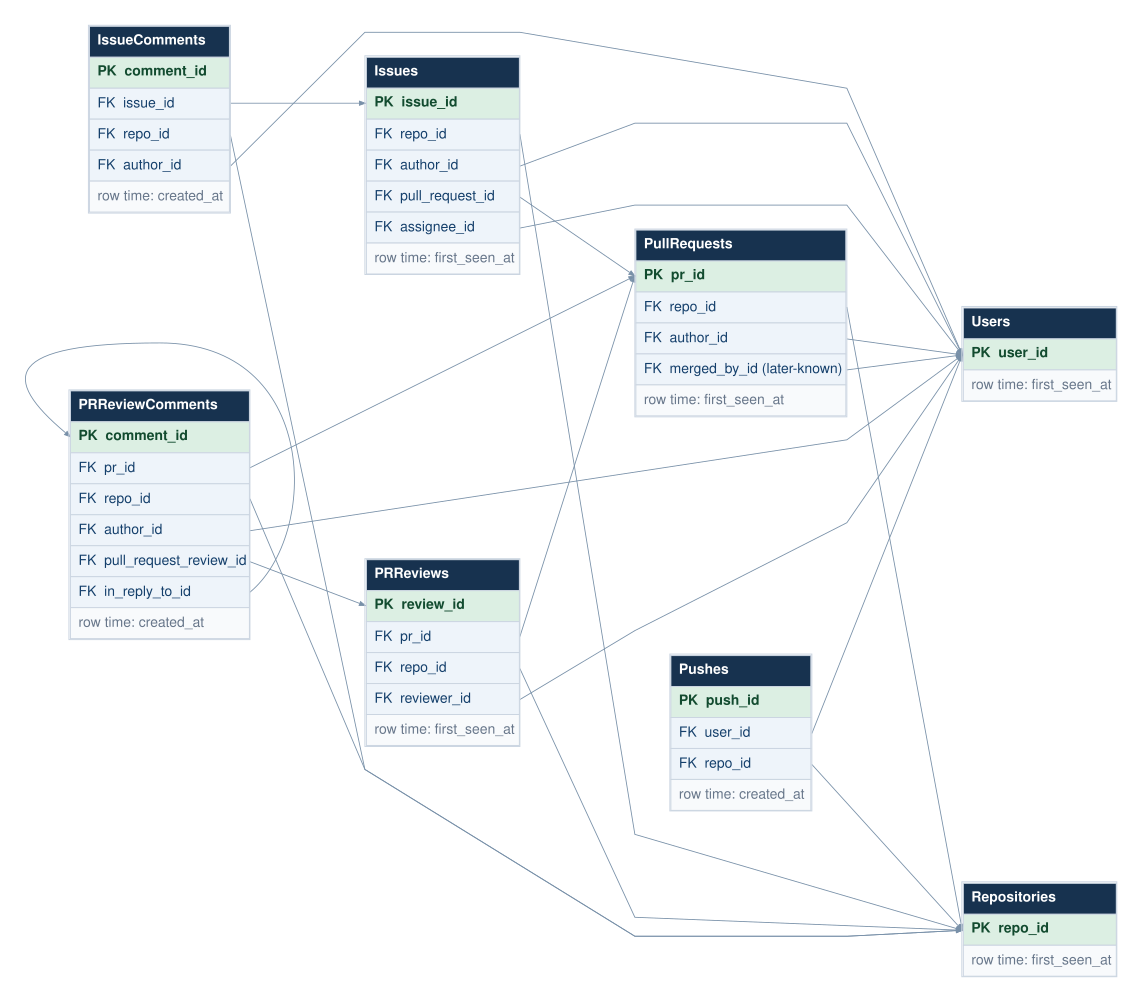

In [145]:
# Step 12 — Q1: Database Schema Graph
# Reuse TABLE_SPECS and FK_RELATIONS from Step 6.

def make_q1_schema():

  # Display names only, not a second schema definition
  display_names = {
      "users": "Users",
      "repos": "Repositories",
      "prs": "PullRequests",
      "issues": "Issues",
      "issue_comments": "IssueComments",
      "reviews": "PRReviews",
      "review_comments": "PRReviewComments",
      "pushes": "Pushes",
  }

  schema = Digraph(
      "schema",
      graph_attr={
          "rankdir": "LR",
          "splines": "polyline",
          "pad": "0.35",
          "nodesep": "0.65",
          "ranksep": "1.6",
          "overlap": "false",
          "outputorder": "edgesfirst",
          "bgcolor": "white",
      },
      node_attr={
          "shape": "plain",
          "fontname": "Helvetica",
      },
      edge_attr={
          "color": "#7890A8",
          "penwidth": "0.85",
          "arrowsize": "0.6",
      }
  )

  # 1. Generate nodes from existing TABLE_SPECS
  for table_name, (pk, time_col) in TABLE_SPECS.items():

      rows = [
          f'<TR><TD BGCOLOR="#17324F" ALIGN="LEFT">'
          f'<FONT COLOR="white"><B>{display_names[table_name]}</B></FONT>'
          f'</TD></TR>',

          f'<TR><TD PORT="{pk}" ALIGN="LEFT" BGCOLOR="#DCEFE3">'
          f'<FONT COLOR="#124B2F"><B>PK  {pk}</B></FONT>'
          f'</TD></TR>',
      ]

      # Get foreign keys from existing FK_RELATIONS
      for child, fk, parent, known_at in FK_RELATIONS:

          if child != table_name:
              continue

          suffix = " (later-known)" if known_at else ""

          rows.append(
              f'<TR><TD PORT="{fk}" ALIGN="LEFT" BGCOLOR="#EEF4FA">'
              f'<FONT COLOR="#143F6B">FK  {fk}{suffix}</FONT>'
              f'</TD></TR>'
          )

      # Show row availability timestamp
      rows.append(
          f'<TR><TD ALIGN="LEFT" BGCOLOR="#F8FAFC">'
          f'<FONT COLOR="#67768A">row time: {time_col}</FONT>'
          f'</TD></TR>'
      )

      label = (
          '<<TABLE BORDER="1" CELLBORDER="1" '
          'CELLSPACING="0" CELLPADDING="7" COLOR="#CBD5E1">'
          + "".join(rows)
          + '</TABLE>>'
      )

      schema.node(table_name, label=label)


  # 2. Generate FK -> PK edges from existing FK_RELATIONS
  for child, fk, parent, known_at in FK_RELATIONS:

      parent_pk = TABLE_SPECS[parent][0]

      schema.edge(
          f"{child}:{fk}:e",
          f"{parent}:{parent_pk}:w",
          constraint="false" if child == parent else "true"
      )

  # 3. Export PNG and SVG
  for fmt in ["png", "svg"]:
      schema.render(
          filename="q1_schema_graph",
          directory=str(output_dir),
          format=fmt,
          cleanup=True
      )

  save_report_figure(schema, "q1_schema_graph")



# Run to create Q1 figure
make_q1_schema()

In [146]:
# Q1 dataset coverage: actual raw files (not just observed table row timestamps).

raw_dir = Path("RAW_DATA_FOLDER")
raw_hour_files = list(raw_dir.glob("????-??-??-*.json.gz"))
raw_hours = []
for path in raw_hour_files:
    parts = path.name[:-8].split("-")  # trim '.json.gz'; YYYY-MM-DD-H
    if len(parts) == 4 and all(x.isdigit() for x in parts):
        y, m, d, h = map(int, parts)
        try:
            raw_hours.append(pd.Timestamp(datetime(y, m, d, h)))
        except (ValueError, OverflowError):
            pass
if raw_hours:
    print("Raw GH Archive coverage (UTC hourly filenames):", min(raw_hours), "to", max(raw_hours))
    print("Number of hourly files:", len(raw_hours), "Unique hours:", len(set(raw_hours)))
else:
    print("Raw files unavailable locally: report the documented original download span.")

# Observed entity rows in the currently loaded 8 Parquet tables
coverage_rows = []
for nt, (pk, time_col) in TABLE_SPECS.items():
    ts = pd.to_datetime(graph_tables[nt][time_col]).dropna()
    coverage_rows.append({"Table": TABLE_DISPLAY[nt], "Rows": len(graph_tables[nt]),
                          "Earliest observed": ts.min(), "Latest observed": ts.max()})
dataset_coverage_report = pd.DataFrame(coverage_rows)
display(dataset_coverage_report)


Raw files unavailable locally: report the documented original download span.


,Table,Rows,Earliest observed,Latest observed
0,Users,14834,2026-06-01 00:00:03,2026-11-11 21:46:59
1,Repositories,48563,2026-06-01 00:00:03,2026-11-11 23:10:44
2,PullRequests,60262,2026-06-01 00:00:44,2026-11-11 23:54:45
3,Issues,38320,2026-06-01 00:02:11,2026-11-11 23:54:55
4,IssueComments,20329,2026-06-01 00:09:54,2026-11-11 23:54:55
5,PRReviews,16387,2026-06-01 00:14:58,2026-11-11 23:54:45
6,PRReviewComments,12061,2026-06-01 00:02:00,2026-11-11 23:48:09
7,Pushes,478598,2026-06-01 00:00:03,2026-11-11 23:11:05


## Q2 — Relational graph modeling (E2, E3 and E3+)

Eight row-level node types, 20 FK relations and their reverse counterparts (40 directed types), with snapshot-time availability checks. E2 uses node-age and simple attributes; E3 fine-tunes graph representations with user-history features; E3+ conditionally adds **numerical** cyclical, repository-history or selective-workflow encodings. The evaluated E3+ variants **do not introduce categorical embeddings**.

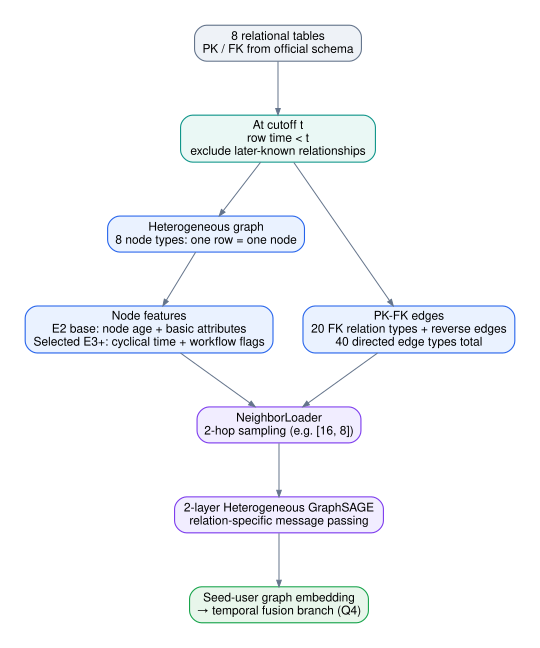

In [160]:
def make_q2_relational():
    # Original first-version styling: vertical flow + blue/purple/green sections.
    g = Digraph("relational", graph_attr={
        "rankdir": "TB", "pad": "0.35", "ranksep": "0.75", "nodesep": "0.42",
        "bgcolor": "white", "fontname": "Helvetica", "fontsize": "15",
    }, node_attr={
        "shape": "box", "style": "rounded,filled", "fontname": "Helvetica",
        "fontsize": "12", "penwidth": "1.1",
    }, edge_attr={"color": "#64748B", "arrowsize": "0.65"})
    g.node("db", f"{len(TABLE_SPECS)} relational tables\nPK / FK from official schema",
           fillcolor="#EEF2F7", color="#64748B")
    g.node("snapshot", "At cutoff t\nrow time < t\nexclude later-known relationships",
           fillcolor="#EAF8F5", color="#0D9488")
    g.node("nodes", f"Heterogeneous graph\n{len(TABLE_SPECS)} node types: one row = one node",
           fillcolor="#EAF2FF", color="#2563EB")
    g.node("fk", f"PK-FK edges\n{len(FK_RELATIONS)} FK relation types + reverse edges\n"
           f"{2 * len(FK_RELATIONS)} directed edge types total",
           fillcolor="#EAF2FF", color="#2563EB")
    g.node(
        "encoding",
        "Node features\n"
        "E2 base: node age + basic attributes\n"
        "Selected E3+: cyclical time + workflow flags",
        fillcolor="#EAF2FF",
        color="#2563EB"
    )
    g.node("sample", "NeighborLoader\n2-hop sampling (e.g. [16, 8])",
           fillcolor="#F1EDFF", color="#7C3AED")
    g.node("gnn", "2-layer Heterogeneous GraphSAGE\nrelation-specific message passing",
           fillcolor="#F1EDFF", color="#7C3AED")
    g.node("user", "Seed-user graph embedding\n→ temporal fusion branch (Q4)",
           fillcolor="#E8F6EB", color="#16A34A")
    for a, b in [("db", "snapshot"), ("snapshot", "nodes"),
                 ("snapshot", "fk"), ("nodes", "encoding"),
                 ("encoding", "sample"), ("fk", "sample"),
                 ("sample", "gnn"), ("gnn", "user")]:
        g.edge(a, b)
    save_report_figure(g, "q2_relational_modeling")

# Run to create Q2 figure
make_q2_relational()

## Q3 — Temporal modeling and availability safeguards

**Graph branch:** relative node age since each row's availability timestamp. **E3+ ablations:** cyclical weekday/hour derived from the available row timestamp (often `first_seen_at`, which is not necessarily the actual event occurrence time), optionally recent repository activity. **User-history branch (E3/E3+):** six activity types × 7/30/90-day counts and distinct repositories, plus six recency values (and missingness flags). Every historical aggregate enforces both event time and row availability before cutoff `t`. Data completeness and delayed observations remain limitations.

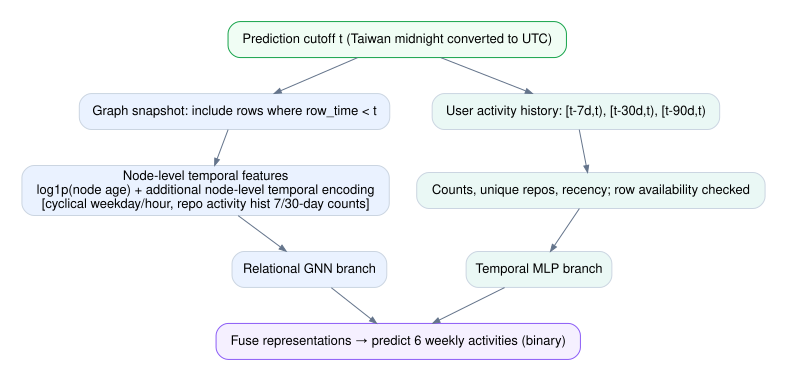

In [189]:
def make_q3_temporal():
    # Original first-version styling: separate temporal GNN and user-history paths.
    g = Digraph("temporal", graph_attr={
        "rankdir": "TB", "pad": "0.3", "nodesep": "0.38", "ranksep": "0.5",
        "bgcolor": "white", "fontname": "Helvetica",
    }, node_attr={
        "shape": "box", "style": "rounded,filled", "fontname": "Helvetica",
        "fontsize": "13", "color": "#CBD5E1", "fillcolor": "#F8FAFC",
    }, edge_attr={"color": "#64748B", "arrowsize": "0.7"})
    g.node("cut", "Prediction cutoff t (Taiwan midnight converted to UTC)",
           fillcolor="#F0FDF4", color="#16A34A")
    g.node("row", "Graph snapshot: include rows where row_time < t", fillcolor="#EAF2FF")
    g.node(
        "node",
        "Node-level temporal features\n"
        "log1p(node age) + additional node-level temporal encoding\n[cyclical weekday/hour, repo activity hist 7/30-day counts]",
        fillcolor="#EAF2FF"
    )
    g.node("window", "User activity history: [t-7d,t), [t-30d,t), [t-90d,t)", fillcolor="#EAF8F5")
    g.node("stats", "Counts, unique repos, recency; row availability checked", fillcolor="#EAF8F5")
    g.node("gnn", "Relational GNN branch", fillcolor="#EAF2FF")
    g.node("mlp", "Temporal MLP branch", fillcolor="#EAF8F5")
    g.node("fusion", "Fuse representations → predict 6 weekly activities (binary)",
           fillcolor="#F5F0FF", color="#8B5CF6")
    for a, b in [("cut", "row"), ("row", "node"), ("node", "gnn"),
                 ("cut", "window"), ("window", "stats"), ("stats", "mlp"),
                 ("gnn", "fusion"), ("mlp", "fusion")]:
        g.edge(a, b)
    save_report_figure(g, "q3_temporal_modeling")

# Run to create Q3 figure
make_q3_temporal()

## Q4 — Full framework: training, benchmark selection and final inference

Data preparation → temporal snapshots/7–30–90d user history → E0/E1/E2/E3/E3+ candidate models → held-out four-week benchmark (September–October) → **select final configuration** → separate final retraining (Aug–Oct 11) and Oct 18 threshold calibration → Nov 22 inference → official submission CSV. The diagram illustrates the graph/temporal candidate path; the automatically selected final model can be simpler (E0/E1/E2/E3). November F1 cannot be calculated without test labels.

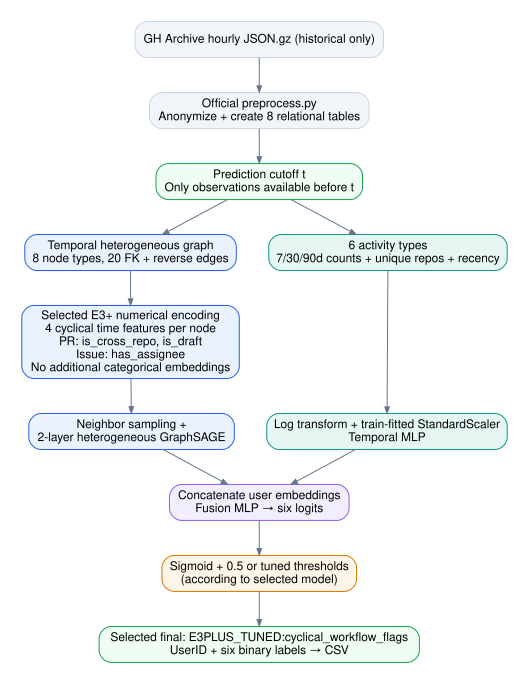

In [152]:
def make_q4_pipeline():
    # Original first-version styling: two branches → fusion → thresholds → CSV.
    g = Digraph("pipeline", graph_attr={
        "rankdir": "TB", "pad": "0.3", "nodesep": "0.45", "ranksep": "0.48",
        "bgcolor": "white", "fontname": "Helvetica",
    }, node_attr={
        "shape": "box", "style": "rounded,filled", "fontname": "Helvetica",
        "fontsize": "12", "fillcolor": "#F8FAFC", "color": "#CBD5E1",
    }, edge_attr={"color": "#64748B", "arrowsize": "0.65"})
    g.node("raw", "GH Archive hourly JSON.gz (historical only)", fillcolor="#F1F5F9")
    g.node("prep", "Official preprocess.py\nAnonymize + create 8 relational tables", fillcolor="#F1F5F9")
    g.node("time", "Prediction cutoff t\nOnly observations available before t", fillcolor="#F0FDF4", color="#16A34A")
    g.node("graph", "Temporal heterogeneous graph\n8 node types, 20 FK + reverse edges", fillcolor="#EAF2FF", color="#2563EB")
    g.node(
        "columns",
        "Selected E3+ numerical encoding\n"
        "4 cyclical time features per node\n"
        "PR: is_cross_repo, is_draft\n"
        "Issue: has_assignee\n"
        "No additional categorical embeddings",
        fillcolor="#EAF2FF",
        color="#2563EB"
    )
    g.node("sample", "Neighbor sampling +\n2-layer heterogeneous GraphSAGE", fillcolor="#EAF2FF", color="#2563EB")
    g.node("stats", "6 activity types\n7/30/90d counts + unique repos + recency", fillcolor="#E6F7F3", color="#0D9488")
    g.node("scale", "Log transform + train-fitted StandardScaler\nTemporal MLP", fillcolor="#E6F7F3", color="#0D9488")
    g.node("fusion", "Concatenate user embeddings\nFusion MLP → six logits", fillcolor="#F2EEFF", color="#8B5CF6")
    g.node("decision", "Sigmoid + 0.5 or tuned thresholds\n(according to selected model)", fillcolor="#FDF6E8", color="#D97706")
    g.node("out", f"Selected final: {final_selected_model}\nUserID + six binary labels → CSV", fillcolor="#F0FDF4", color="#16A34A")
    for a, b in [("raw", "prep"), ("prep", "time"), ("time", "graph"),
                 ("time", "stats"), ("graph", "columns"), ("columns", "sample"),
                 ("stats", "scale"), ("sample", "fusion"), ("scale", "fusion"),
                 ("fusion", "decision"), ("decision", "out")]:
        g.edge(a, b)
    save_report_figure(g, "q4_full_pipeline")

# Run to create Q4 figure
make_q4_pipeline()

In [165]:
# !zip -r /content/final_model_artifacts.zip /content/assignment2/final_model_artifacts

# from google.colab import files
# files.download('/content/final_model_artifacts.zip')


updating: content/assignment2/final_model_artifacts/ (stored 0%)
updating: content/assignment2/final_model_artifacts/final_weights.pt (deflated 19%)
updating: content/assignment2/final_model_artifacts/final_temporal_scaler.joblib (deflated 39%)
updating: content/assignment2/final_model_artifacts/final_config.joblib (deflated 64%)
  adding: content/assignment2/final_model_artifacts/final_calibration_activity_f1.csv (deflated 47%)
  adding: content/assignment2/final_model_artifacts/final_calibration_score_comparison.csv (deflated 28%)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [154]:
# !zip -r /content/benchmark_runs.zip /content/assignment2/benchmark_runs

# from google.colab import files
# files.download('/content/benchmark_runs.zip')


  adding: content/assignment2/benchmark_runs/ (stored 0%)
  adding: content/assignment2/benchmark_runs/benchmark_cyclical_repo_activity_20261117T211623370998Z_config.joblib (deflated 68%)
  adding: content/assignment2/benchmark_runs/benchmark_cyclical_workflow_flags_20261117T212056073141Z.csv (deflated 71%)
  adding: content/assignment2/benchmark_runs/benchmark_cyclical_only_20261117T211141640320Z_config.joblib (deflated 65%)
  adding: content/assignment2/benchmark_runs/benchmark_cyclical_only_20261117T211141640320Z.csv (deflated 69%)
  adding: content/assignment2/benchmark_runs/benchmark_cyclical_workflow_flags_20261117T212056073141Z_config.joblib (deflated 64%)
  adding: content/assignment2/benchmark_runs/benchmark_cyclical_workflow_flags_20261117T212056073141Z_e3plus.pt (deflated 21%)
  adding: content/assignment2/benchmark_runs/benchmark_cyclical_repo_activity_20261117T211623370998Z.csv (deflated 71%)
  adding: content/assignment2/benchmark_runs/benchmark_cyclical_repo_activity_202

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [190]:
# !zip -r /content/report_figures.zip /content/report_figures/

# from google.colab import files
# files.download('/content/report_figures.zip')


updating: content/report_figures/ (stored 0%)
updating: content/report_figures/q2_relational_modeling.svg (deflated 74%)
updating: content/report_figures/q1_schema_graph.png (deflated 4%)
updating: content/report_figures/.ipynb_checkpoints/ (stored 0%)
updating: content/report_figures/q4_full_pipeline.svg (deflated 75%)
updating: content/report_figures/q2_relational_modeling.png (deflated 5%)
updating: content/report_figures/q1_schema_graph.svg (deflated 87%)
updating: content/report_figures/q4_full_pipeline.png (deflated 3%)
  adding: content/report_figures/q3_temporal_modeling.svg (deflated 71%)
  adding: content/report_figures/q3_temporal_modeling.png (deflated 2%)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>